# 06 · Web 后端基础（Java 操作数据库）


来源：[飞书讲义《06-Web后端基础(java操作数据库)》](https://heuqqdmbyk.feishu.cn/wiki/WgPdwfw7PiWSd5knBiYcWE1aneM)。整理日期：2026-09-28。

正文沿用讲义顺序，保留知识说明、AI 提示词、38 段原代码、57 张配图和 1 张嵌入知识表格；影响理解或跟练的地方就近标注“补充”“勘误”。配图已内嵌，可离线阅读；课程推广内容未收录。原讲义中的局部代码与迭代版本应按步骤使用，不要一次全部复制成同一个类。

第 5 节补齐 JDBC、MyBatis 注解、XML 与 YAML 的完整跟练示例，第 6、7 节提供排错和复习。Java、SQL、配置与终端命令分别放回对应工程或工具中执行；配图所引用的课程 JAR 不是 Notebook 附件。


## 本章学习路线（补充）

第 05 章通过客户端发送 SQL；本章让 Java 程序完成相同的数据库操作。先理解 JDBC 的底层步骤，再看 MyBatis 把哪些重复步骤交给框架。

| 顺序 | 要解决的问题 | 核心内容 |
| --- | --- | --- |
| 连接 | Java 怎样找到数据库并建立会话？ | JDBC、驱动、Connection、URL |
| 安全执行 | 怎样把输入作为数据传给 SQL？ | PreparedStatement、参数绑定、SQL 注入 |
| 处理结果 | 查询和更新的返回值怎么用？ | ResultSet、executeQuery、executeUpdate |
| 简化代码 | 谁负责绑定参数和封装结果？ | MyBatis Mapper、注解 CRUD、@Param |
| 复用连接 | 每次操作都要新建物理连接吗？ | DataSource、HikariCP、Druid |
| 管理 SQL 与配置 | SQL 变复杂、配置变多后放哪里？ | XML 映射、properties、YAML |

```text
业务调用 → Mapper → MyBatis → JDBC 驱动 → MySQL
                         ↘ DataSource 连接池提供连接
```

跟练前提：已能用客户端连接 MySQL，并掌握 SELECT、INSERT、UPDATE、DELETE；Java 侧沿用 Maven 与 JUnit 的工程习惯。


## 1 前言

在前面我们学习MySQL数据库时，都是利用图形化客户端工具(如：idea、datagrip)，来操作数据库的。

我们做为后端程序开发人员，通常会使用Java程序来完成对数据库的操作。Java程序操作数据库的技术呢，有很多啊，而最为底层、最为基础的就是JDBC。

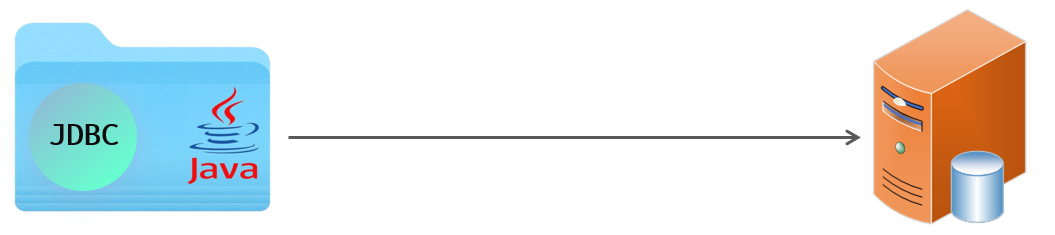

<strong>JDBC：</strong>（Java DataBase Connectivity），就是使用Java语言操作关系型数据库的一套API。 【是操作数据库最为基础、底层的技术】

但是使用JDBC来操作数据库，会比较繁琐，所以现在在企业项目开发中呢，一般都会使用基于JDBC的封装的高级框架，比如：Mybatis、MybatisPlus、Hibernate、SpringDataJPA。 

而这些技术，目前的市场占有份额如下图所示：

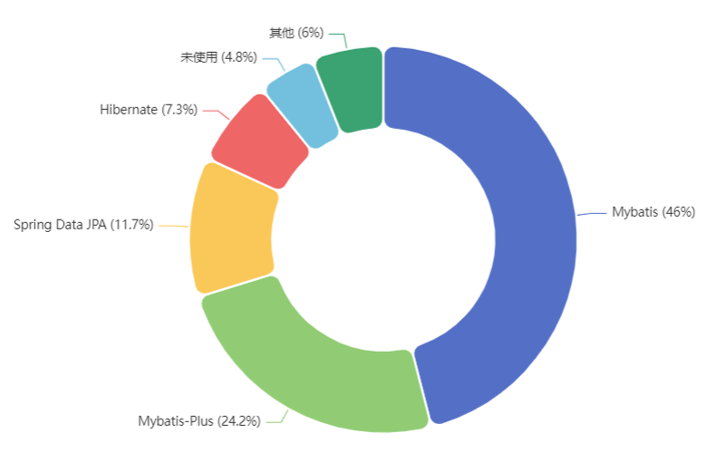

从上图中，我们也可以看到，目前最为主流的就是Mybatis，其次是MybatisPlus。

> **补充：**上图是课程当时的统计截图，未给出统计范围和采样方法，不作为当前市场份额结论。本章先理解 JDBC，再用 MyBatis 简化重复代码；MyBatis-Plus 在后续课程学习。

所以，在我们的课程体系中呢，这两种主流的操作数据库的框架我们都要学习。 而我们在学习这两个主流的框架之前，还需要学习一下操作数据库的基础基础 JDBC。 然后接下来，再来学习Mybatis。 而在我们后面的课程中，我们还要学习MybatisPlus框架。 那么今天呢，我们就先来学习 JDBC 和 Mybatis。

> <strong>今天课程安排：</strong>
> 
> 1. JDBC
> 2. Mybatis
> 3. SpringBoot配置文件


## 2 JDBC


### 2.1 介绍

<strong>JDBC：（Java DataBase Connectivity），就是使用</strong><strong>Java语言操作关系型数据库的一套API</strong><strong>。</strong>

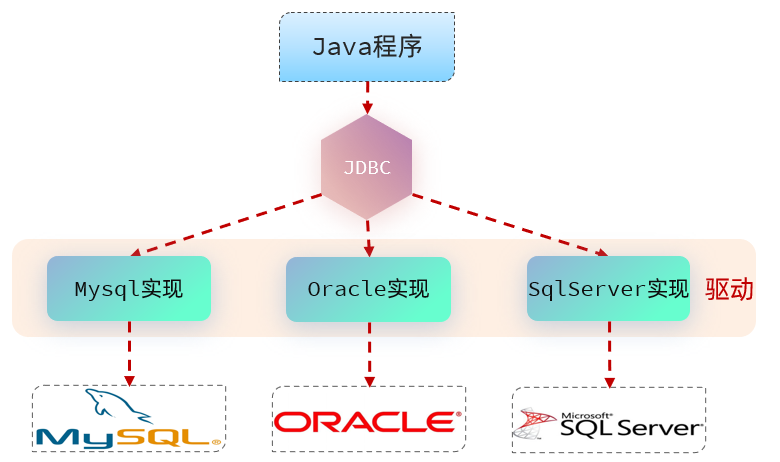

<strong>本质：</strong>

- sun公司官方定义的一套操作所有关系型数据库的规范，即接口。
- 各个数据库厂商去实现这套接口，提供数据库驱动jar包。
- 我们可以使用这套接口(JDBC)编程，真正执行的代码是驱动jar包中的实现类。

**补充：接口、驱动和数据库的关系。**JDBC 接口主要位于 JDK 的 `java.sql`、`javax.sql` 包中；MySQL Connector/J 是实现这些接口的驱动，不是 MySQL 服务端。

```text
Java 业务代码 → JDBC API → MySQL Connector/J → MySQL Server → 库/表
```

有 JDK 仍需引入数据库驱动，并连接已运行的数据库服务。现代 JDBC 驱动通常通过服务发现自动注册，常见 Maven 工程不必再手写 `Class.forName`；切换数据库也不意味着 SQL 方言、URL 和类型映射完全不用改。

那有了JDBC之后，我们就可以直接在java代码中来操作数据库了，只需要编写这样一段java代码，就可以来操作数据库中的数据。 示例代码如下：

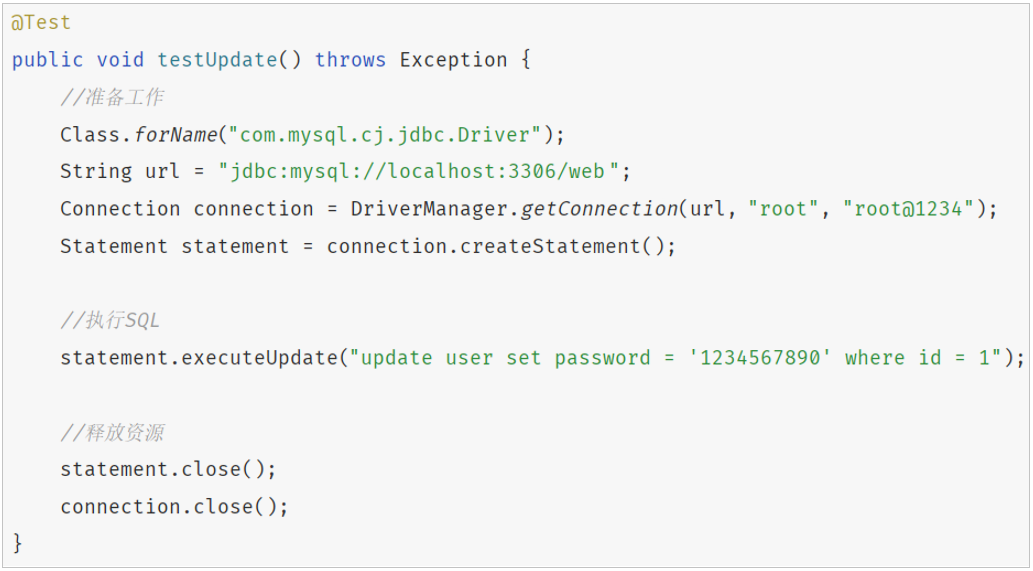


### 2.2 查询数据


#### 2.2.1 需求

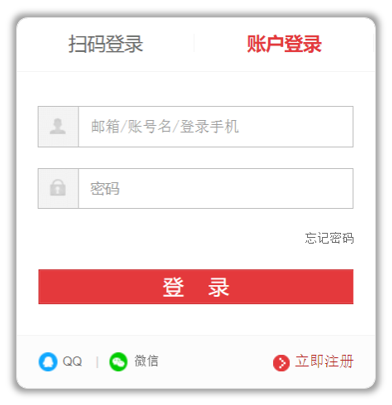

<strong>需求：</strong>基于JDBC实现用户登录功能。

<strong>本质：</strong>其本质呢，其实就是基于JDBC程序，执行如下select语句，并将查询的结果输出到控制台。SQL语句：

````sql
select * from user where username = 'linchong' and password = '123456';
````

> **跟练提示：**下面初始化的 5 条数据中没有 `linchong`，因此这条 SQL 返回 0 行是正常的。后面的 Java 示例统一查询 `daqiao / 123456`，应得到“大乔”。这里演示 SQL 查询流程，真实登录应按用户名查询用户，再用密码哈希校验库核对密码，不能照搬明文密码存储。


#### 2.2.2 准备工作

1). 创建一个maven项目

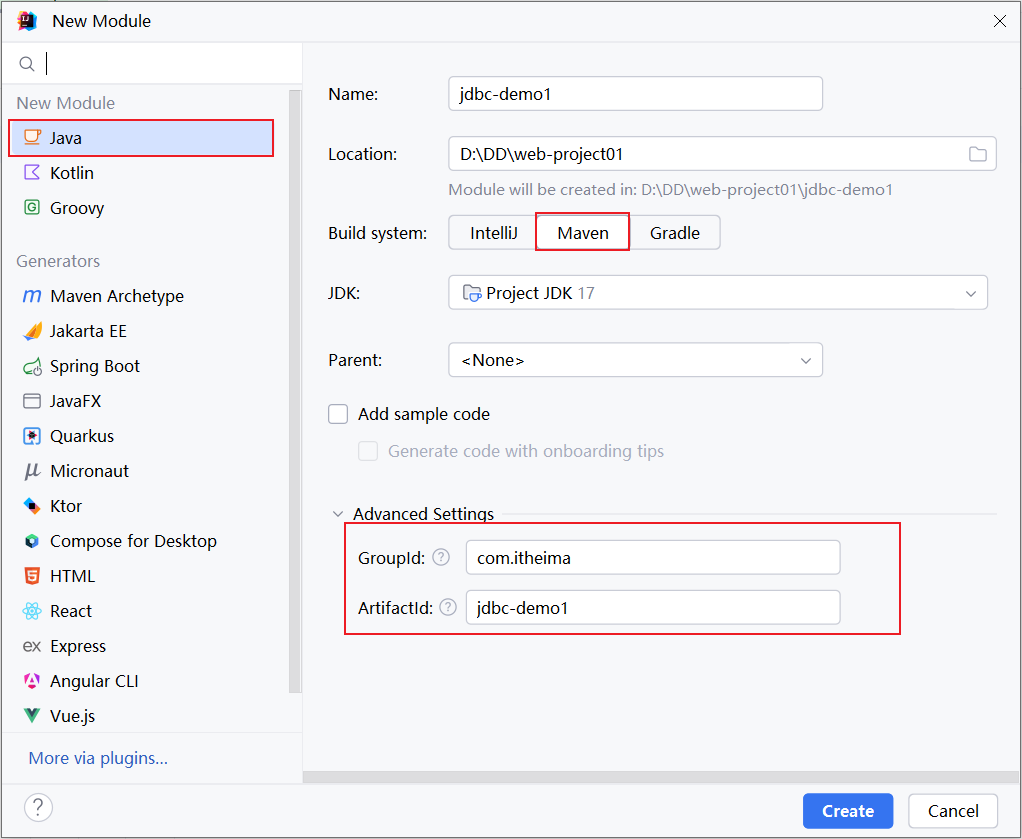

2). 创建一个数据库 web，并在该数据库中创建user表

````sql
create table user(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) comment '用户名',
    password varchar(32) comment '密码',
    name varchar(10) comment '姓名',
    age tinyint unsigned comment '年龄'
) comment '用户表';

insert into user(id, username, password, name, age) values (1, 'daqiao', '123456', '大乔', 22),
                                                           (2, 'xiaoqiao', '123456', '小乔', 18),
                                                           (3, 'diaochan', '123456', '貂蝉', 24),
                                                           (4, 'lvbu', '123456', '吕布', 28),
                                                           (5, 'zhaoyun', '12345678', '赵云', 27);
````

**补充：先选库，再建表。**上面的脚本只有建表和插入数据，没有创建 `web` 库。首次跟练时先执行：

```sql
CREATE DATABASE web CHARACTER SET utf8mb4;
USE web;
```

已有 `web` 时直接切换并检查表，不要重复插入固定主键。`web.user` 是本课程的业务表，别与系统库的 `mysql.user` 混淆；`user` 在这里可以使用，第 5 节独立练习改用 `javaweb06_practice.users`，避免把旧练习的数据混在一起。


#### 2.2.3 代码实现

> <strong>AI提示词（prompt）：</strong>
> 
> 你是一名java开发工程师，帮我基于JDBC程序来操作数据库，执行如下SQL语句：
> 
> select &#42; from user where username = 'daqiao' and password = '123456'

<strong>具体的代码为：</strong>

1). 在 pom.xml 文件中引入依赖

````xml
<dependencies>
    <!-- MySQL JDBC driver -->
    <dependency>
        <groupId>mysql</groupId>
        <artifactId>mysql-connector-java</artifactId>
        <version>8.0.30</version>
    </dependency>

    <dependency>
        <groupId>org.junit.jupiter</groupId>
        <artifactId>junit-jupiter</artifactId>
        <version>5.9.3</version>
        <scope>test</scope>
    </dependency>
</dependencies>
````

> **版本补充：**这是旧版依赖片段，不是完整 POM。新坐标使用 `com.mysql:mysql-connector-j`；普通 Maven 工程需写版本，Spring Boot 工程可以让父 POM 管理驱动版本。不要只改 artifactId 却漏改 groupId。JUnit 测试仍需 Maven/IDEA 识别测试目录和 JUnit 5；第 5 节给出完整项目配置。

2). 在 <code>src/main/test/java</code> 目录下编写测试类，定义测试方法

> **勘误：**Maven 标准测试目录是 `src/test/java`，不是 `src/main/test/java`。下方省略的 JDBC 类型需要从 `java.sql` 导入，`@Test` 来自 `org.junit.jupiter.api.Test`。

````java
public class JDBCTest {

    /**
     * 编写JDBC程序, 查询数据
     */
    @Test
    public void testJdbc() throws Exception {
        // 获取连接
        Connection conn = DriverManager.getConnection("jdbc:mysql://localhost:3306/web", "root", "1234");
        // 创建预编译的PreparedStatement对象
        PreparedStatement pstmt = conn.prepareStatement("SELECT * FROM user WHERE username = ? AND password = ?");
        // 设置参数
        pstmt.setString(1, "daqiao"); // 第一个问号对应的参数
        pstmt.setString(2, "123456"); // 第二个问号对应的参数
        // 执行查询
        ResultSet rs = pstmt.executeQuery();
        // 处理结果集
        while (rs.next()) {
            int id = rs.getInt("id");
            String uName = rs.getString("username");
            String pwd = rs.getString("password");
            String name = rs.getString("name");
            int age = rs.getInt("age");

            System.out.println("ID: " + id + ", Username: " + uName + ", Password: " + pwd + ", Name: " + name + ", Age: " + age);
        }
        // 关闭资源
        rs.close();
        pstmt.close();
        conn.close();
    }

}
````

**补充：这段代码要看懂的 6 步。**获取 `Connection` → 创建 `PreparedStatement` → 绑定参数 → 执行 → 读取 `ResultSet` → 释放资源。参数下标从 **1** 开始，与 `?` 的出现顺序对应。

原例只在方法正常执行到底时关闭资源；中途抛异常可能泄漏。实际编写时使用第 5.2 节的 `try-with-resources`，把结果集、语句和连接按使用层次声明，退出时自动逆序关闭。URL 中的 `web` 必须是已建好的库；`root / 1234` 是示例账号密码，应替换为本机配置并通过环境变量等方式传入。不要把查询出的密码打印到日志。

而上述的单元测试中，我们在SQL语句中，将将 用户名 和密码的值都写死了，而这两个值应该是动态的，是将来页面传递到服务端的。 那么，我们可以基于前面所讲解的JUnit中的参数化测试进行单元测试，代码改造如下：

````java
public class JDBCTest {

    /**
     * 编写JDBC程序, 查询数据
     */
    @ParameterizedTest
    @CsvSource({"daqiao,123456"})
    public void testJdbc(String _username, String _password) throws Exception {
        // 获取连接
        Connection conn = DriverManager.getConnection("jdbc:mysql://localhost:3306/web", "root", "1234");
        // 创建预编译的PreparedStatement对象
        PreparedStatement pstmt = conn.prepareStatement("SELECT * FROM user WHERE username = ? AND password = ?");
        // 设置参数
        pstmt.setString(1, _username); // 第一个问号对应的参数
        pstmt.setString(2, _password); // 第二个问号对应的参数
        // 执行查询
        ResultSet rs = pstmt.executeQuery();
        // 处理结果集
        while (rs.next()) {
            int id = rs.getInt("id");
            String uName = rs.getString("username");
            String pwd = rs.getString("password");
            String name = rs.getString("name");
            int age = rs.getInt("age");

            System.out.println("ID: " + id + ", Username: " + uName + ", Password: " + pwd + ", Name: " + name + ", Age: " + age);
        }
        // 关闭资源
        rs.close();
        pstmt.close();
        conn.close();
    }

}
````

> **补充：**`@ParameterizedTest` 来自 `org.junit.jupiter.params`，`@CsvSource` 来自其 `provider` 子包；`junit-jupiter` 聚合依赖包含参数化测试支持。一组 CSV 值会触发一次方法调用，但只有输出没有断言，还不能自动判断结果对错。这里连着真实 MySQL，更准确地说是数据库集成测试。

如果在测试时，需要传递一组参数，可以使用  <code>@</code><code>CsvSource</code> 注解。


#### 2.2.4 代码剖析


##### 2.2.4.1 ResultSet

ResultSet（结果集对象）：封装了DQL查询语句查询的结果。

- next()：将光标从当前位置向前移动一行，并判断当前行是否为有效行，返回值为boolean。

    - true：有效行，当前行有数据
    - false：无效行，当前行没有数据
- getXxx(…)：获取数据，可以根据列的编号获取，也可以根据列名获取（推荐）。

结果解析步骤：

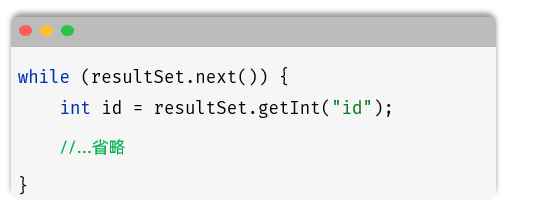

**配图要点：**光标开始位于第一行之前，必须先调用 `next()` 才能取当前行的数据；每次 `while (rs.next())` 消费一行。列编号也从 1 开始，使用列名/别名通常更易维护。`getInt("age")` 遇到 SQL NULL 会给出 0，需要 `wasNull()` 区分；也可以用支持该转换的驱动调用 `getObject("age", Integer.class)` 保留空值。


##### 2.2.4.2 预编译SQL

其实我们在编写SQL语句的时候，有两种风格：

- 静态SQL（参数硬编码）

````java
conn.prepareStatement("SELECT * FROM user WHERE username = 'daqiao' AND password = '123456'");
ResultSet resultSet = pstmt.executeQuery();
````

这种呢，就是参数值，直接拼接在SQL语句中，参数值是写死的。

- 预编译SQL（参数动态传递）

````java
conn.prepareStatement("SELECT * FROM user WHERE username = ? AND password = ?");
pstmt.setString(1, "daqiao");
pstmt.setString(2, "123456");
ResultSet resultSet = pstmt.executeQuery();
````

> **勘误：**上面两段对比代码都省略了赋值，完整首行应为 `PreparedStatement pstmt = conn.prepareStatement(...);`，否则 `pstmt` 没有定义。参数中实际使用的是半角 `?`；不要给占位符再套 SQL 引号，也不能用它代替表名、列名或 ASC/DESC 关键字。

这种呢，并未将参数值在SQL语句中写死，而是使用 ？ 进行占位，然后再指定每一个占位符对应的值是多少，而最终在执行SQL语句的时候，程序会将SQL语句（SELECT &#42; FROM user WHERE username = ? AND password = ?），以及参数值（"daqiao", "123456"）都发送给数据库，然后在执行的时候，会使用参数值，将？占位符替换掉。

> **理解修正：**“替换问号”只是便于理解的说法。关键是由驱动按参数类型绑定数据，使参数内容不能改变 SQL 结构，而不是自己用字符串 replace 拼回 SQL。MySQL Connector/J 可以采用客户端或服务端预处理，是否在服务端提前编译取决于驱动配置。

那这种预编译的SQL，也是在项目开发中推荐使用的SQL语句。主要的作用有两个：

- 防止SQL注入
- 性能更高

那接下来，我们就来介绍一下这两点。


###### 2.2.4.2.1 SQL注入

- SQL注入：通过控制输入来修改事先定义好的SQL语句，以达到执行代码对服务器进行攻击的方法。 

SQL注入最典型的场景，就是用户登录功能。

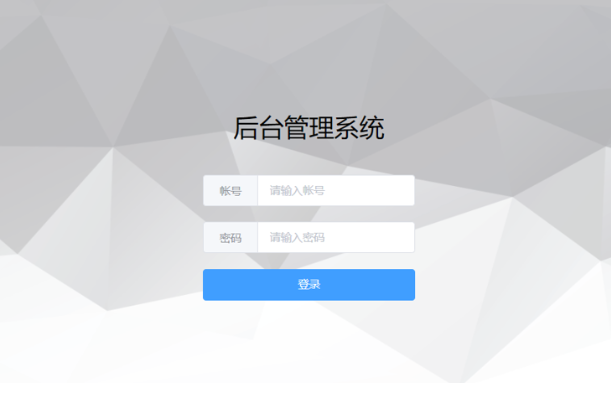

<strong>注入演示：</strong>

1). 打开课程资料中的文件夹 <code>资料/02. SQL注入演示</code>，运行其中的jar包 <code>sql&#95;Injection&#95;demo-0.0.1-SNAPSHOT.jar</code>，进入该目录后，执行命令：

````text
java -jar sql_Injection_demo-0.0.1-SNAPSHOT.jar
````

> **操作补充：**`java -jar ...` 在终端运行，不是 Java 源代码。这里的两个演示 JAR 来自课程配套资料，不包含在笔记中；没有 JAR 也可通过下方 SQL 对比理解原理。两个服务都使用 9090 时应一次运行一个。

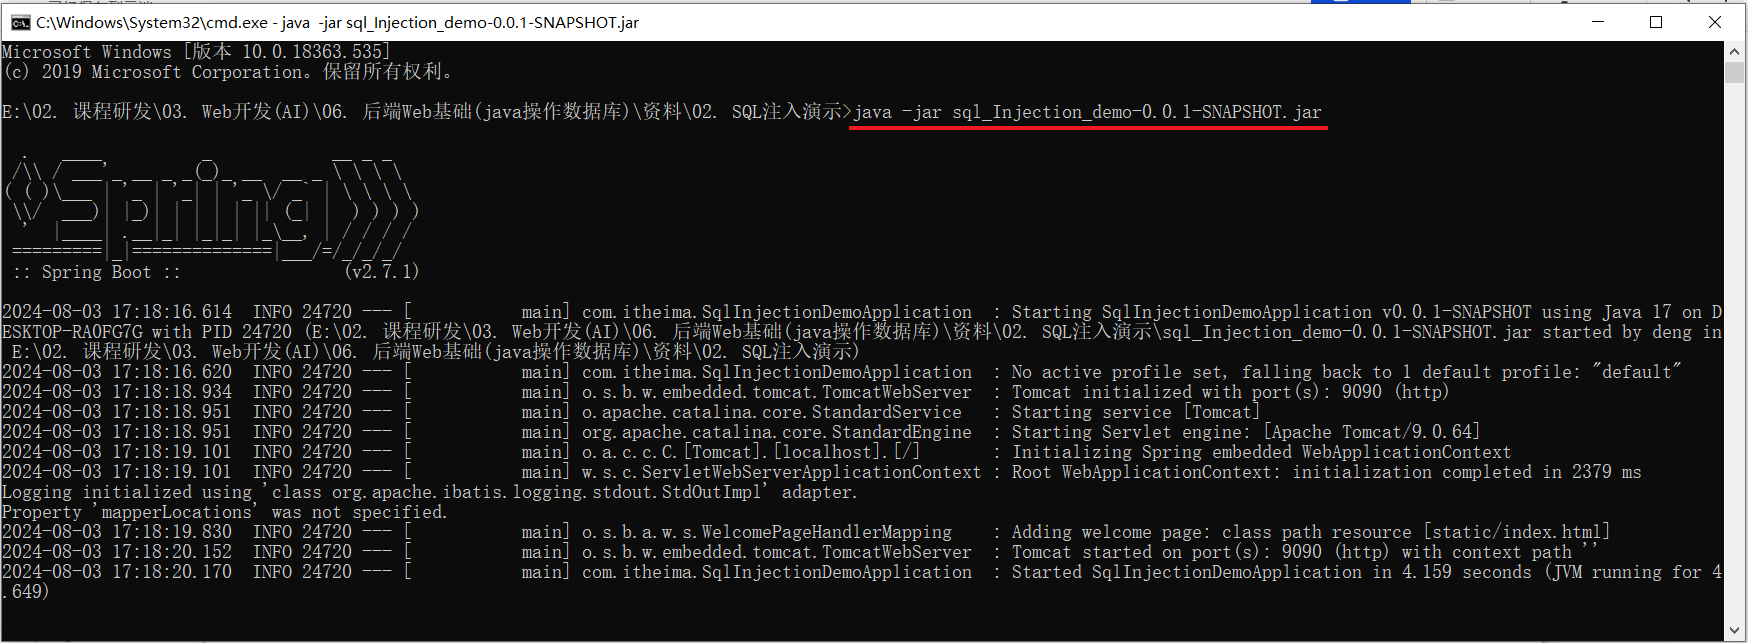

2). 打开浏览器访问 http://localhost:9090/ ，必须登录后才能访问到系统。我们先测试正常的用户名和密码

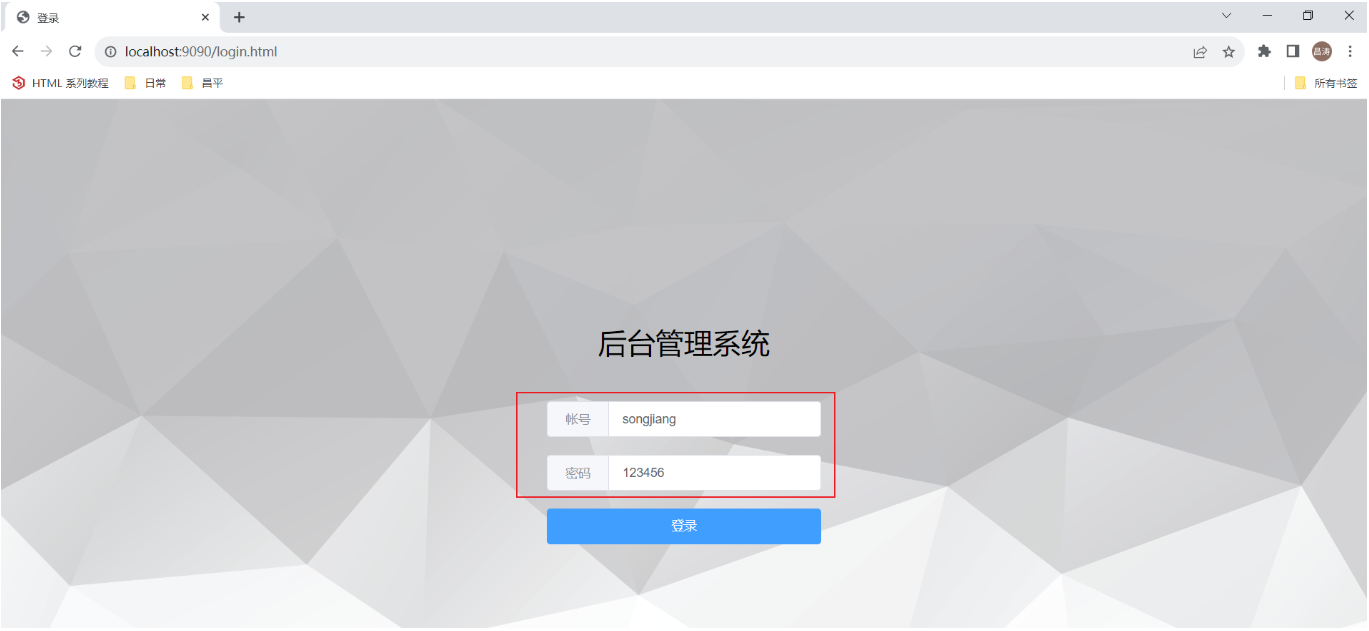

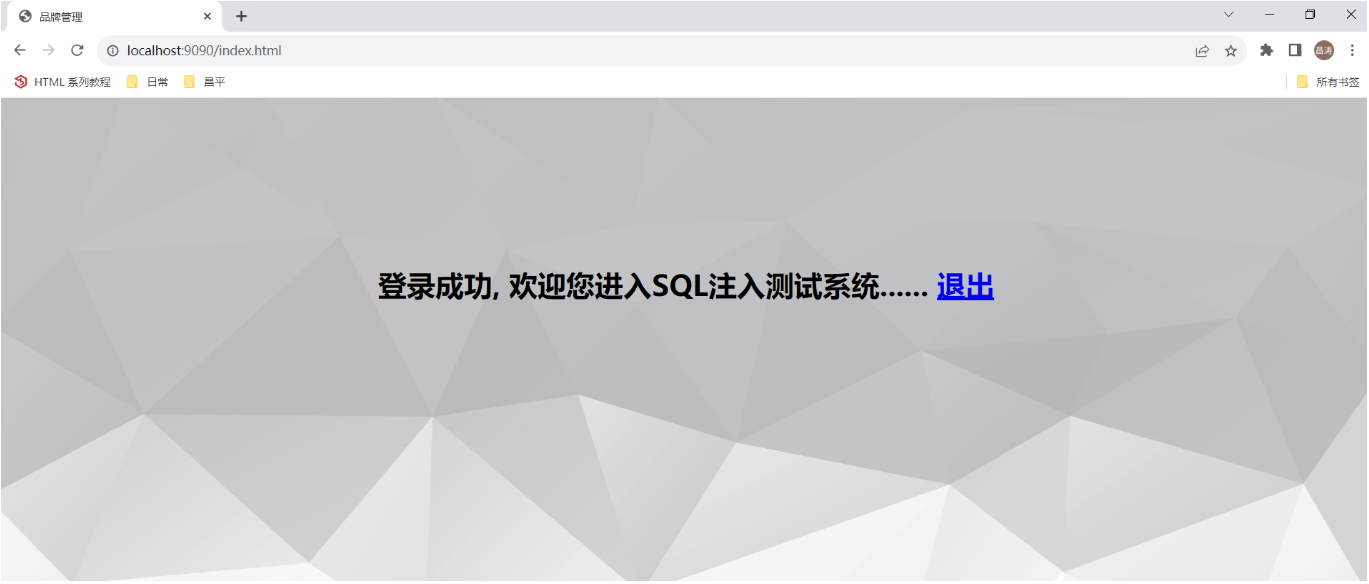

3). 接下来，我们再来测试一下错误的用户名和密码 。

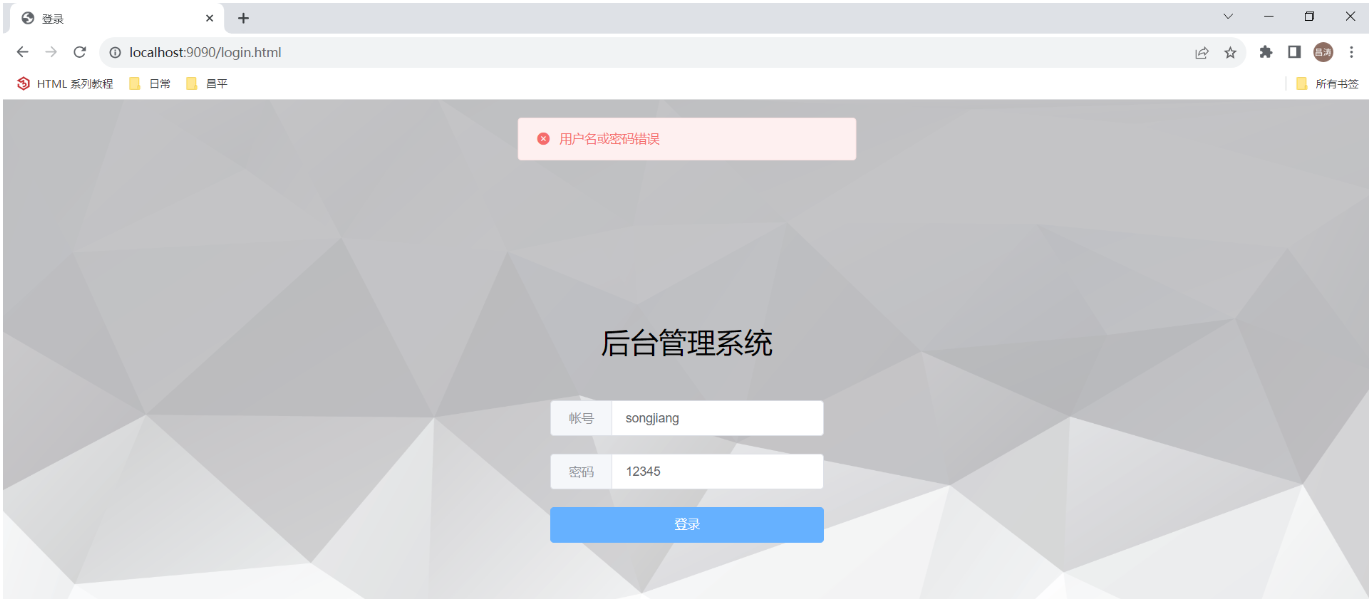

我们看到，如果用户名密码错误，是不能进入到系统中进行访问的，会提示 <code>用户名和密码错误</code>。

4). 那接下来，我们就要演示一下SQL注入现象，我们可以通过控制表单输入，来修改事先定义好的SQL语句的含义。 从而来攻击服务器。

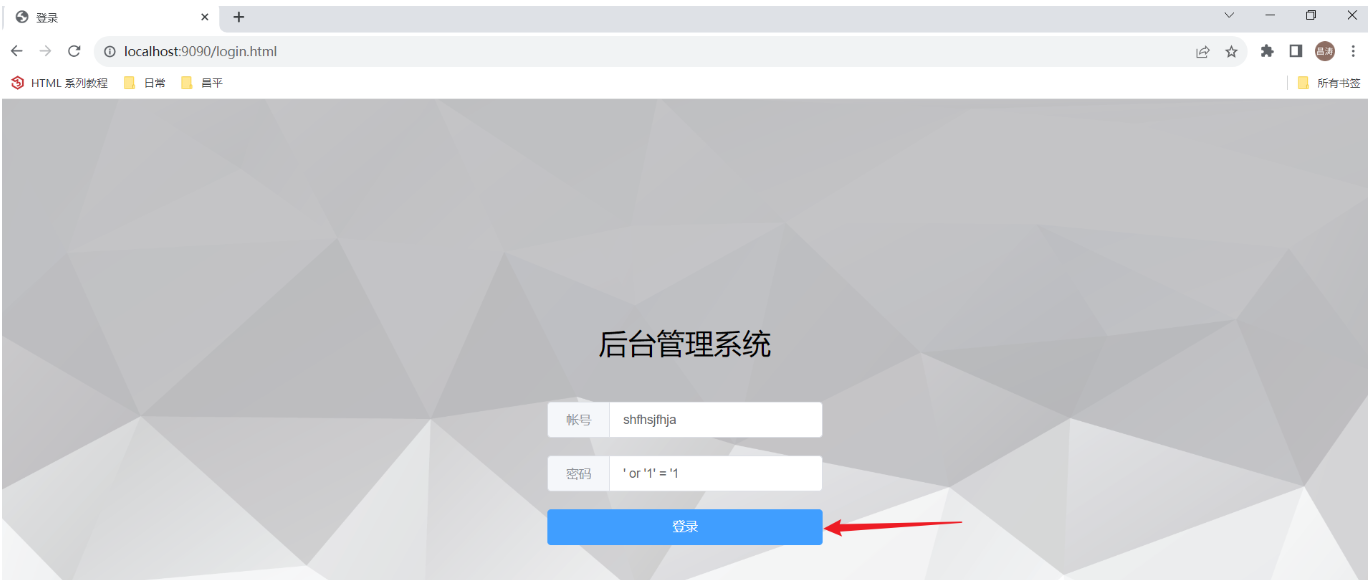

点击登录后，我们看到居然可以成功进入到系统中。

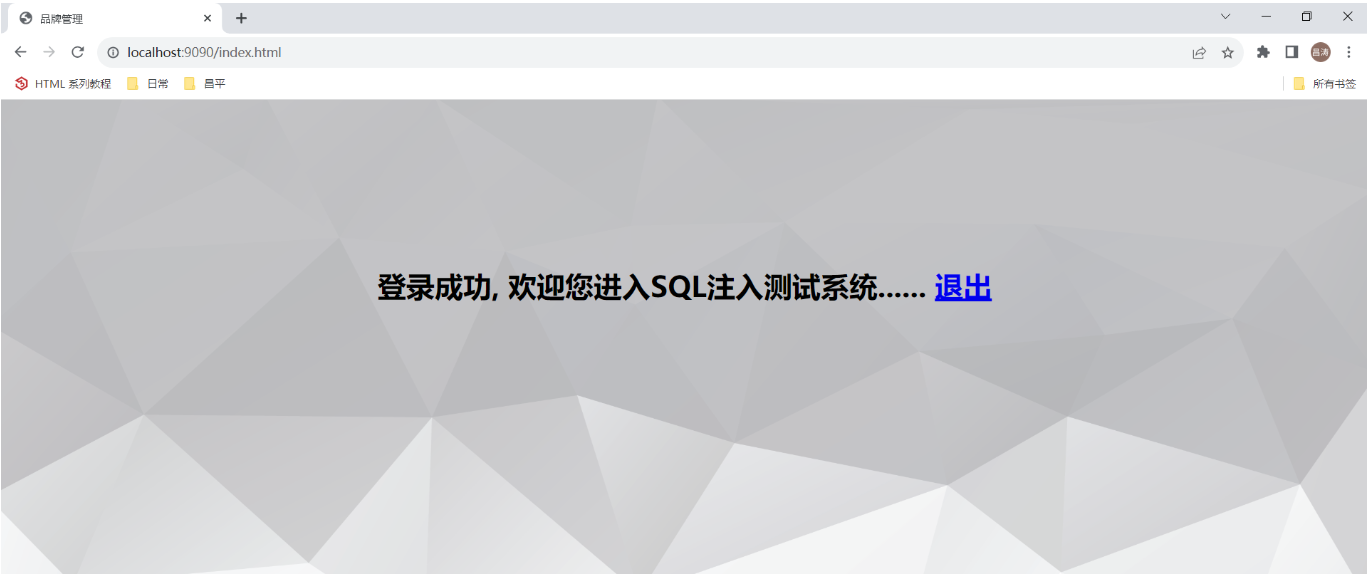

为什么会出现这种现象呢？

在进行登录操作时，怎么样才算登录成功呢？ 如果我们查询到了数据，就说明用户名密码是对的。 如果没有查询到数据，就说明用户名或密码错误。

而出现上述现象，原因就是因为，我们我们编写的SQL语句是基于字符串进行拼接的 。 我们输入的用户名无所谓，比如：<code>shfhsjfhja</code> ，而密码呢，就是我们精心设计的，如：<code>' or '1' = '1</code> 。

那最终拼接的SQL语句，如下所示：

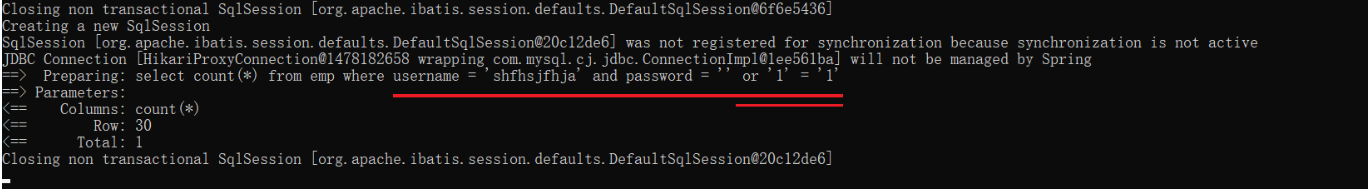

**配图转写：只在本章练习数据上理解这个输入。**当密码输入为 `' or '1' = '1`，字符串拼接可能得到：

```sql
SELECT * FROM user
WHERE username = 'shfhsjfhja' AND password = '' OR '1' = '1';
```

AND 的优先级高于 OR，最后的恒真条件让筛选失效。改用 `WHERE username = ? AND password = ?` 并调用 `setString` 时，这段输入只是一整个密码字符串，无法成为 SQL 条件。预编译只保护正确绑定的参数；SQL 其他部分若继续拼接不受信任输入，仍有风险。

我们知道，<code>or</code> 连接的条件，是或的关系，两者满足其一就可以。 所以，虽然用户名密码输入错误，也是可以查询返回结果的，而只要查询到了数据，就说明用户名和密码是正确的。


###### 2.2.4.2.2 SQL注入解决

而通过预编译SQL（select &#42; from user where username = ? and password = ?），就可以直接解决上述SQL注入的问题。 接下来，我们再来演示一下，通过预编译SQL是否能够解决SQL注入问题。

1). 打开课程资料中的文件夹 <code>资料/02. SQL注入演示</code>，运行其中的jar包 <code>sql&#95;prepared&#95;demo-0.0.1-SNAPSHOT.jar</code>，进入该目录后，执行命令：

````text
java -jar sql_prepared_demo-0.0.1-SNAPSHOT.jar
````

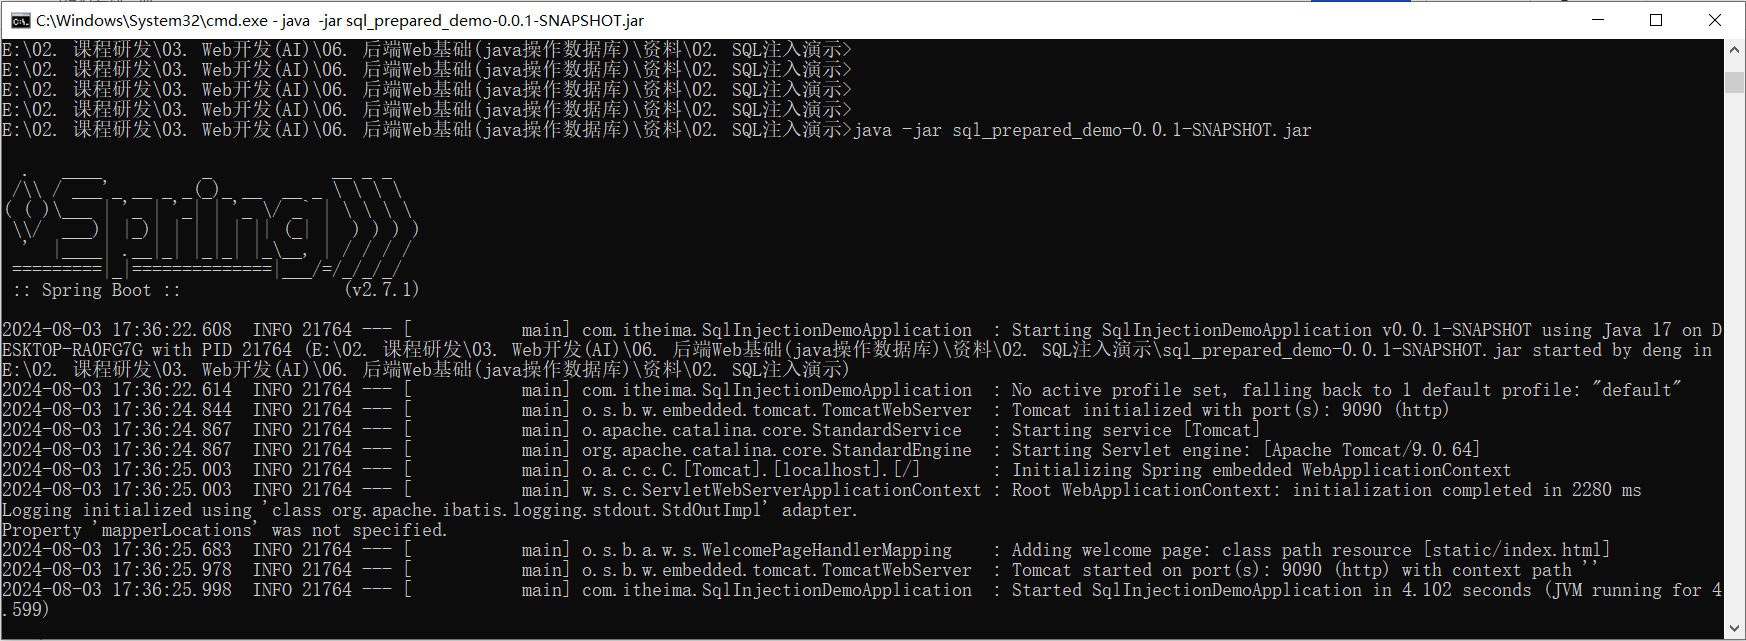

2). 打开浏览器访问 <code>http://localhost:9090/</code> ，必须登录后才能访问到系统 。我们先测试正常的用户名和密码 

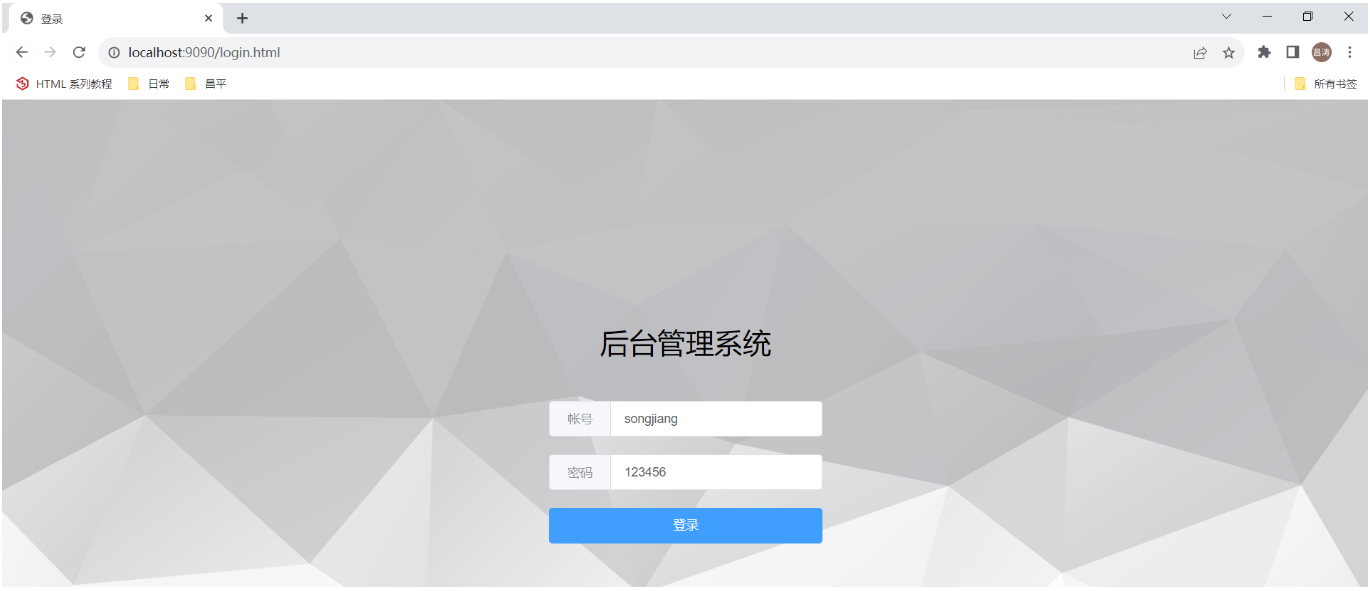

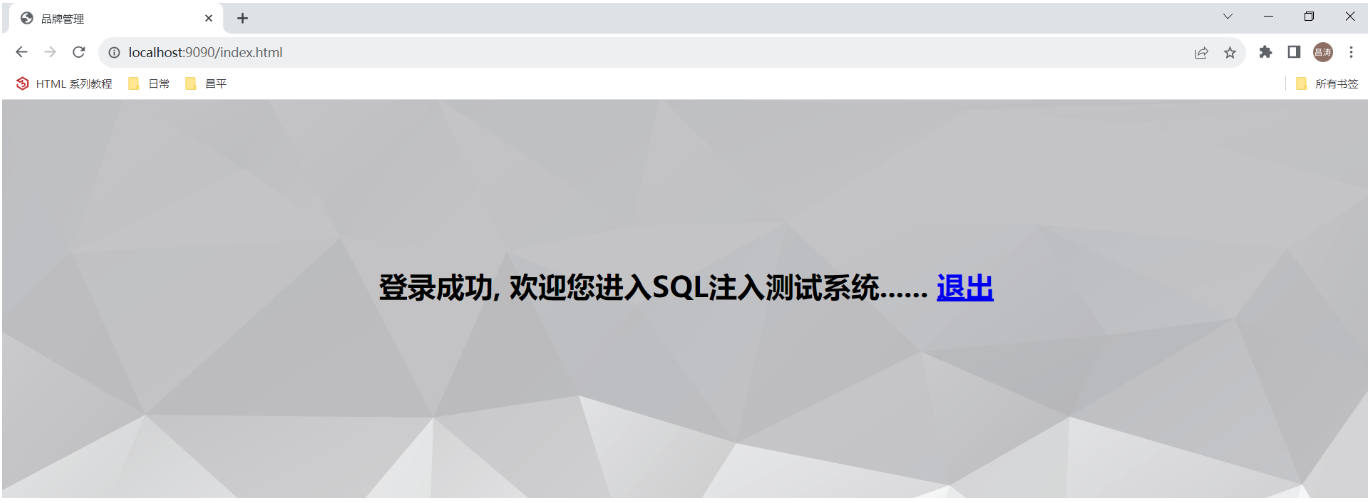

3). 那接下来，我们就要演示一下是否可以基于上述的密码 <code>' or '1' = '1</code>，来完成SQL注入 。

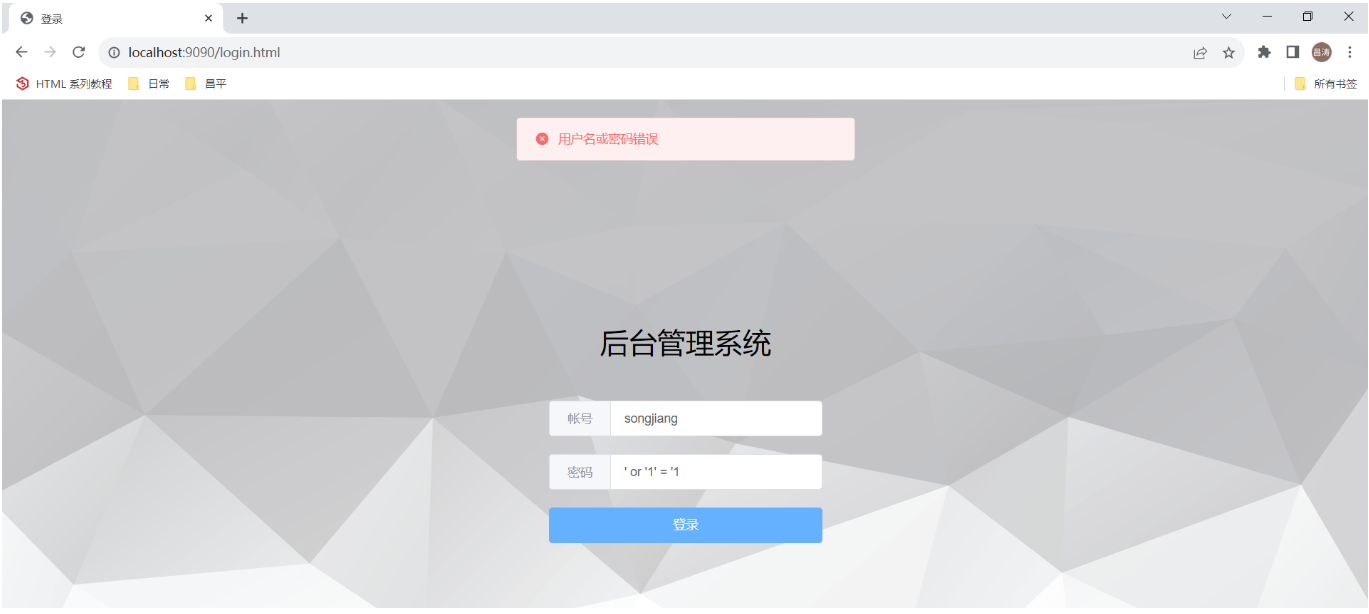

通过控制台，可以看到输入的SQL语句，是预编译SQL语句。

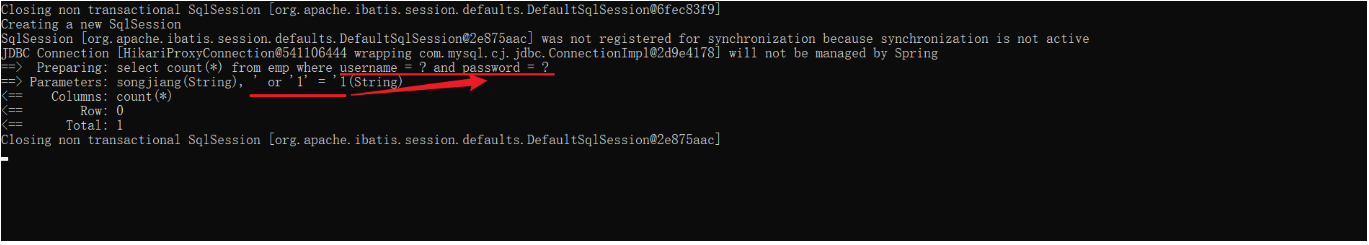

而在预编译SQL语句中，当我们执行的时候，会把整个<code>' or '1'='1</code>作为一个完整的参数，赋值给第2个问号（<code>' or '1'='1</code>进行了转义，只当做字符串使用）

那么此时再查询时，就查询不到对应的数据了，登录失败。

> <strong>注意：在以后的项目开发中，我们使用的基本全部都是预编译SQL语句。 </strong>


###### 2.2.4.2.3 性能更高

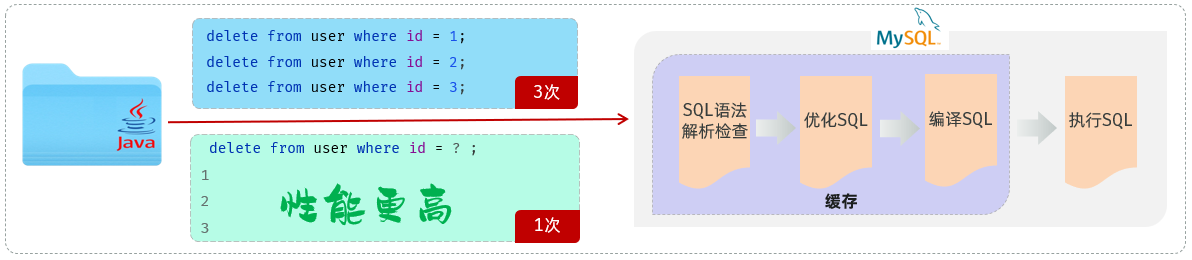

> **性能勘误：**图中“相同结构的 SQL 可复用解析/执行准备工作”是优化思路，不代表调用一次 `prepareStatement` 就必然更快。收益受服务端预处理、驱动缓存、连接复用、执行次数和数据库实现影响。选择参数绑定的首要理由是安全与类型处理，不要把参数绑定、语句缓存和连接池当成同一种技术。


### 2.3 增删改数据


#### 2.3.1 需求

- 需求：基于JDBC程序，执行如下update语句。
- SQL：

````sql
update user set password = '123456', gender = 2 where id = 1;
````

**勘误：**本章 `user` 表没有 `gender` 字段。下方 Java 实际更新的是 `age`，按它的测试参数应改成：

```sql
UPDATE user SET password = '123456', age = 25 WHERE id = 1;
```

后面 AI 提示词也沿用了 gender 笔误，生成代码前先对照表结构。


#### 2.3.2 代码实现

> <strong>AI提示词（prompt）：</strong>
> 
> 你是一名java开发工程师，帮我基于JDBC程序来操作数据库，执行如下SQL语句：
> 
> update user set password = '123456', gender = 2 where id = 1;

代码实现如下：

````java
@ParameterizedTest
@CsvSource({"1,123456,25"})
public void testUpdate(int userId, String newPassword, int newAge) throws Exception {
    // 建立数据库连接
    Connection conn = DriverManager.getConnection("jdbc:mysql://localhost:3306/web", "root", "1234");
    // SQL 更新语句
    String sql = "UPDATE user SET password = ?, age = ? WHERE id = ?";
    // 创建预编译的PreparedStatement对象
    PreparedStatement pstmt = conn.prepareStatement(sql);

    // 设置参数
    pstmt.setString(1, newPassword); // 第一个问号对应的参数
    pstmt.setInt(2, newAge);      // 第二个问号对应的参数
    pstmt.setInt(3, userId);         // 第三个问号对应的参数

    // 执行更新
    int rowsUpdated = pstmt.executeUpdate();

    // 输出结果
    System.out.println(rowsUpdated + " row(s) updated.");

    // 关闭资源
    pstmt.close();
    conn.close();
}
````

> **补充：**SELECT 用 `executeQuery()` 获取结果集；INSERT、UPDATE、DELETE 用 `executeUpdate()` 获取行数。更新同样应使用 try-with-resources。返回 0 不一定是程序异常，可能没有匹配记录；MySQL 更新计数还受驱动“匹配行/实际改变行”设置影响，不能单凭行数判断字段一定改变。新 JDBC 连接通常默认自动提交，每条 DML 执行成功即提交；跨多条语句的事务在后续学习。

> - JDBC程序执行DML语句：int rowsUpdated = pstmt.executeUpdate();  //返回值是影响的记录数
> - JDBC程序执行DQL语句：ResultSet resultSet = pstmt.executeQuery(); //返回值是查询结果集


## 3 Mybatis


### 3.1 介绍

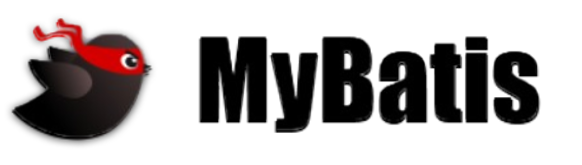

什么是MyBatis?

- MyBatis是一款优秀的 <strong>持久层</strong> <strong>框架</strong>，用于简化JDBC的开发。
- MyBatis本是 Apache的一个开源项目iBatis，2010年这个项目由apache迁移到了google code，并且改名为MyBatis 。2013年11月迁移到Github。
- 官网：https://mybatis.org/mybatis-3/zh/index.html 

在上面我们提到了两个词：一个是持久层，另一个是框架。

- 持久层：指的是就是数据访问层(dao)，是用来操作数据库的。

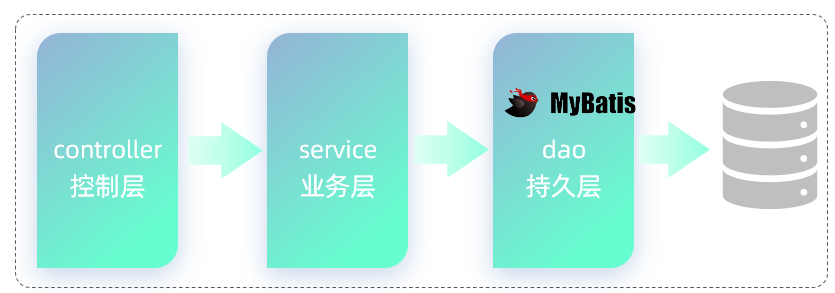

- 框架：是一个半成品软件，是一套可重用的、通用的、软件基础代码模型。在框架的基础上进行软件开发更加高效、规范、通用、可拓展。

通过Mybatis就可以大大简化原生的JDBC程序的代码编写，比如 通过 <code>select &#42; from user</code> 查询所有的用户数据，通过JDBC程序操作呢，需要大量的代码实现，而如果通过Mybatis实现相同的功能，只需要简单的三四行就可以搞定。

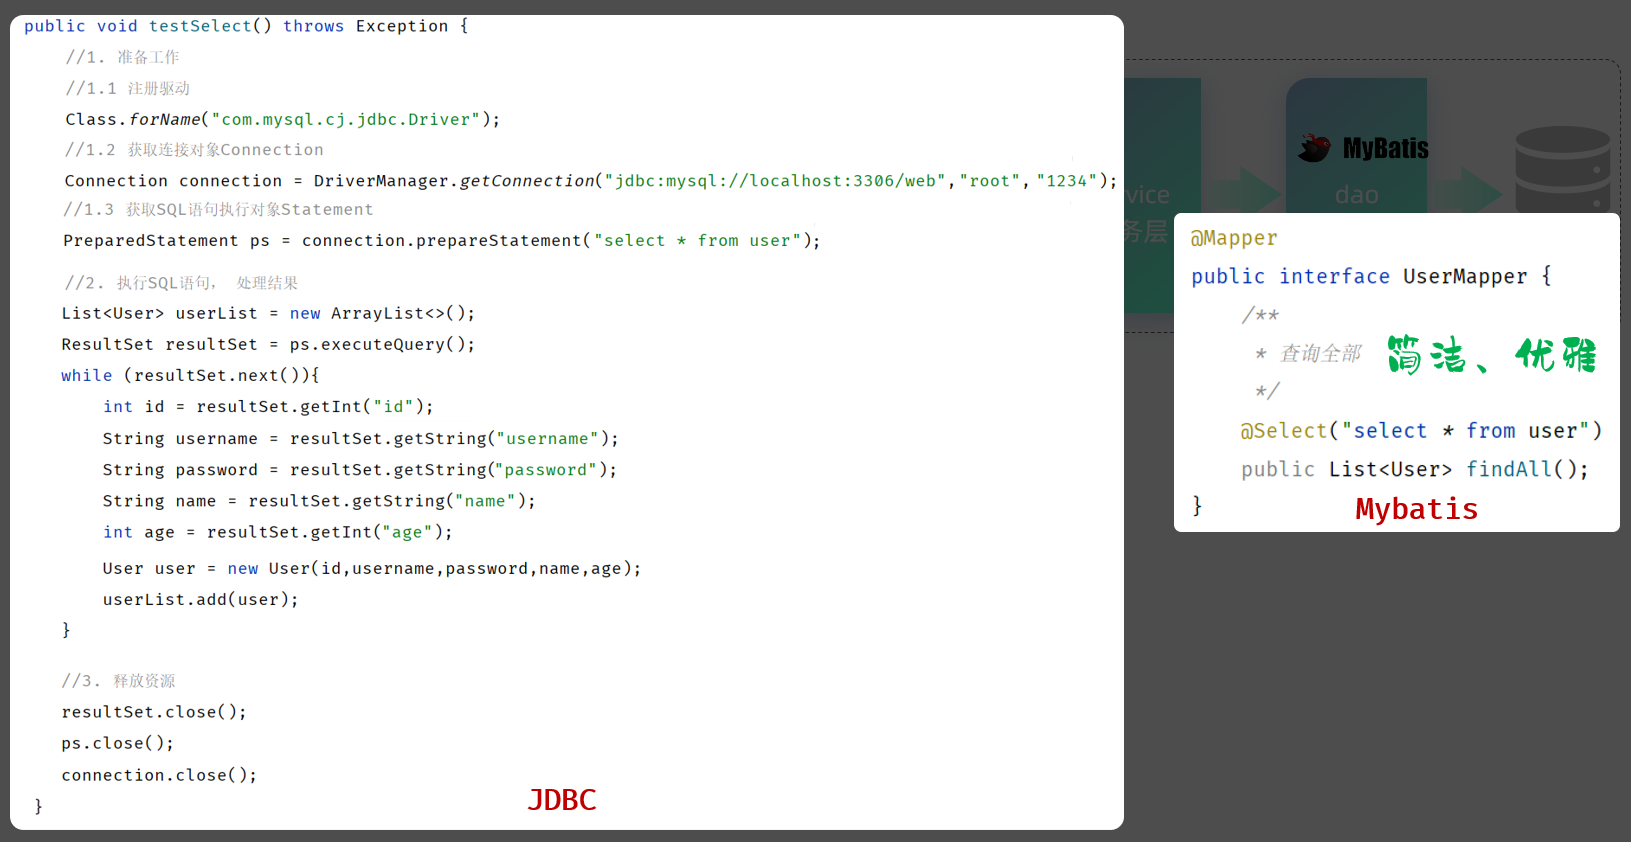


#### 3.1.1 快速入门

需求：使用Mybatis查询所有用户数据 。

<strong>1). 创建springboot工程，并导入 mybatis的起步依赖、mysql的驱动包、lombok。</strong>

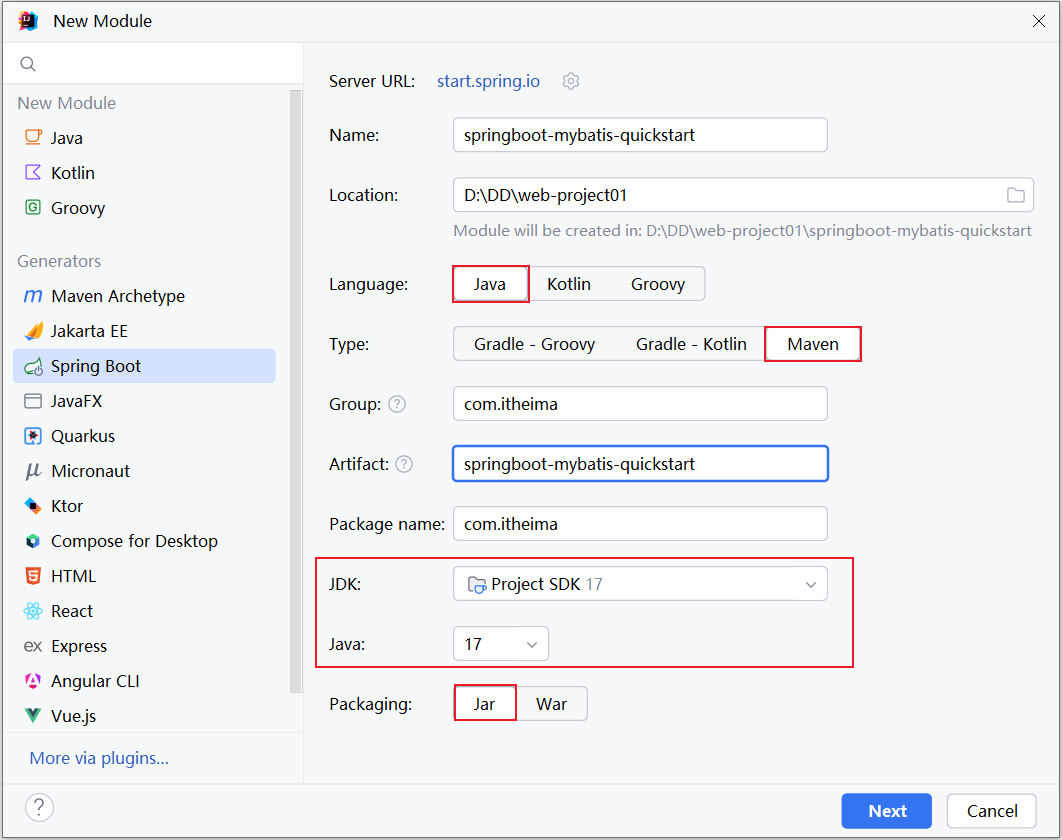

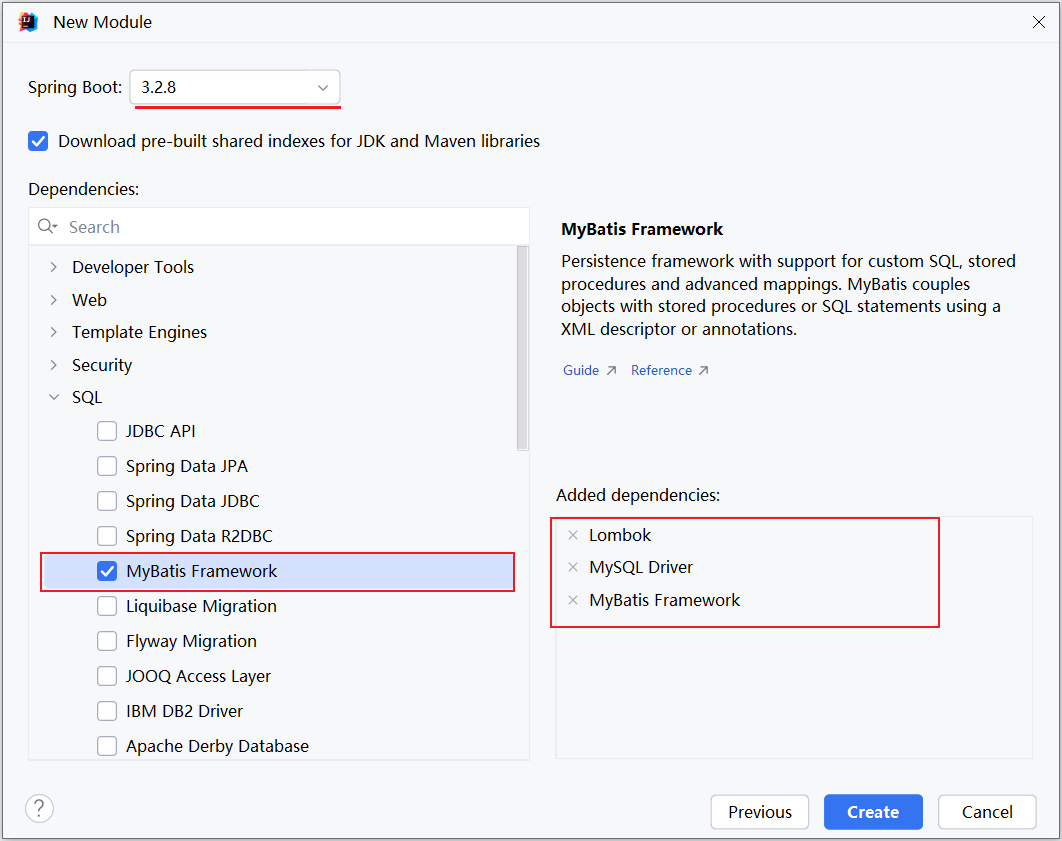

项目工程创建完成后，自动在pom.xml文件中，导入Mybatis依赖和MySQL驱动依赖。如下所示：

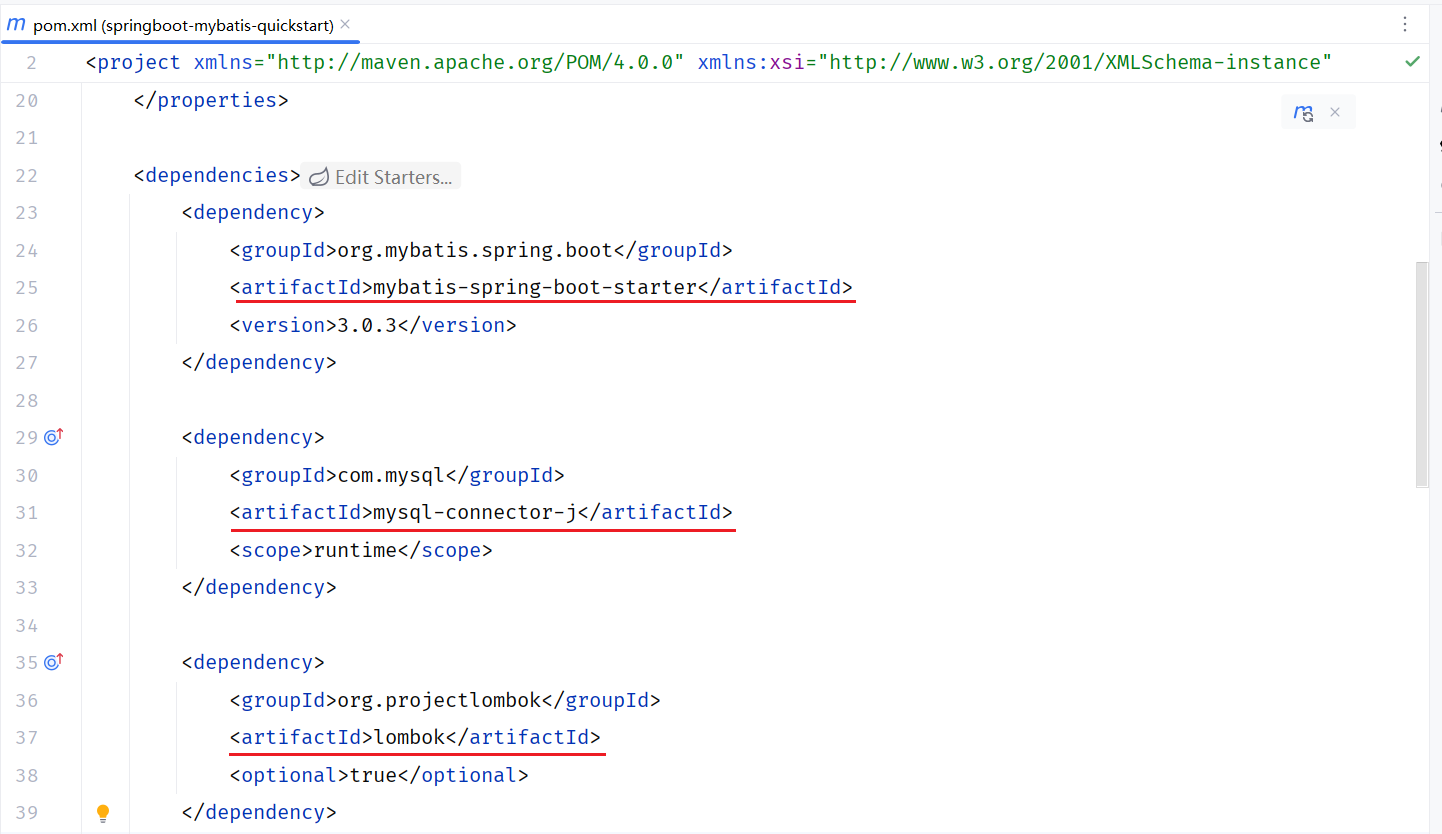

**配图补充：**关键依赖为 `org.mybatis.spring.boot:mybatis-spring-boot-starter`、`com.mysql:mysql-connector-j`、`org.projectlombok:lombok` 和测试 starter。需让 JDK、Spring Boot 与 MyBatis starter 的大版本匹配：本章补充项目固定 Java 17、Spring Boot 3.2.0、MyBatis starter 3.0.3，用于复现课程；不能直接把当前 Initializr 默认选中的 Boot 大版本与旧截图依赖混搭。版本对应关系可查 [MyBatis Starter 官方兼容表](https://mybatis.org/spring-boot-starter/mybatis-spring-boot-autoconfigure/)。

<strong>2). 数据准备：创建用户表user，并创建对应的实体类User。</strong>

- 用户表 user（如果已经存在，就不用创建了）

````sql
create table user(
    id int unsigned primary key auto_increment comment 'ID,主键',
    username varchar(20) comment '用户名',
    password varchar(32) comment '密码',
    name varchar(10) comment '姓名',
    age tinyint unsigned comment '年龄'
) comment '用户表';

insert into user(id, username, password, name, age) values (1, 'daqiao', '123456', '大乔', 22),
                                                           (2, 'xiaoqiao', '123456', '小乔', 18),
                                                           (3, 'diaochan', '123456', '貂蝉', 24),
                                                           (4, 'lvbu', '123456', '吕布', 28),
                                                           (5, 'zhaoyun', '12345678', '赵云', 27);
````

- 实体类：实体类的属性名与表中的字段名一一对应。 实体类放在 <code>com.itheima.pojo</code> 包下。

````java
@Data
@NoArgsConstructor
@AllArgsConstructor
public class User {
    private Integer id; //ID
    private String username; //用户名
    private String password; //密码
    private String name; //姓名
    private Integer age; //年龄
}
````

> **补充：**`@Data`、`@NoArgsConstructor`、`@AllArgsConstructor` 来自 Lombok，会在编译时生成访问方法和构造方法；需引入依赖并启用注解处理。包装类型 `Integer` 可以表示数据库 NULL。`@Data` 默认生成的 toString 会包含 password，示例只用于本地演示；第 5 节排除密码输出。列名与 Java 属性名不一致时，要用 SQL 别名、resultMap，或合适的命名转换配置，不能期待所有名称都自动匹配。

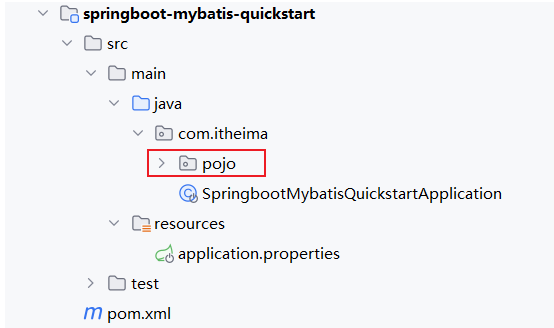

<strong>3). 配置Mybatis</strong>

在 <code>application.properties</code> 中配置数据库的连接信息。

````properties
#数据库访问的url地址
spring.datasource.url=jdbc:mysql://localhost:3306/web
#数据库驱动类类名
spring.datasource.driver-class-name=com.mysql.cj.jdbc.Driver
#访问数据库-用户名
spring.datasource.username=root
#访问数据库-密码
spring.datasource.password=root@1234
````

上述的配置，可以直接复制过去，不要敲错了。 全部都是 <code>spring.datasource.xxxx</code> 开头。

> **配置勘误：**键名可照写，值必须核对。本章前后出现 `web` / `web01` 和 `1234` / `root@1234`，并非要求来回换库或密码。原讲义跟练统一选你已创建的 `web`；补充项目统一用 `javaweb06_practice`，账号密码取本机实际值。

<strong>4). 编写Mybatis程序：编写Mybatis的持久层接口，定义SQL语句（注解）</strong>

在创建出来的springboot工程中，在引导类所在包下，在创建一个包 <code>mapper</code> 。在 <code>mapper</code> 包下创建一个接口 <code>UserMapper</code> ，这是一个持久层接口（Mybatis的持久层接口规范一般都叫 XxxMapper）。

UserMapper接口的内容如下：

````java
import com.itheima.pojo.User;
import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Select;
import java.util.List;

@Mapper
public interface UserMapper {
    /**
     * 查询全部
     */
    @Select("select * from user")
    public List<User> findAll();
}
````

> <strong>注解说明：</strong>
> 
> - @Mapper注解：表示是mybatis中的Mapper接口
> 
> 程序运行时，框架会自动生成接口的实现类对象(代理对象)，并给交Spring的IOC容器管理
> 
> - @Select注解：代表的就是select查询，用于书写select查询语句

<strong>5). 单元测试</strong>

在创建出来的SpringBoot工程中，在src下的test目录下，已经自动帮我们创建好了测试类 ，并且在测试类上已经添加了注解 <code>@SpringBootTest</code>，代表该测试类已经与SpringBoot整合。 

该测试类在运行时，会自动通过引导类加载Spring的环境（IOC容器）。我们要测试那个bean对象，就可以直接通过<code>@Autowired</code>注解直接将其注入进行，然后就可以测试了。 

测试类代码如下：

````java
@SpringBootTest
class SpringbootMybatisQuickstartApplicationTests {

    @Autowired
    private UserMapper userMapper;

    @Test
    public void testFindAll(){
        List<User> userList = userMapper.findAll();
        for (User user : userList) {
            System.out.println(user);
        }
    }
}
````

运行结果：

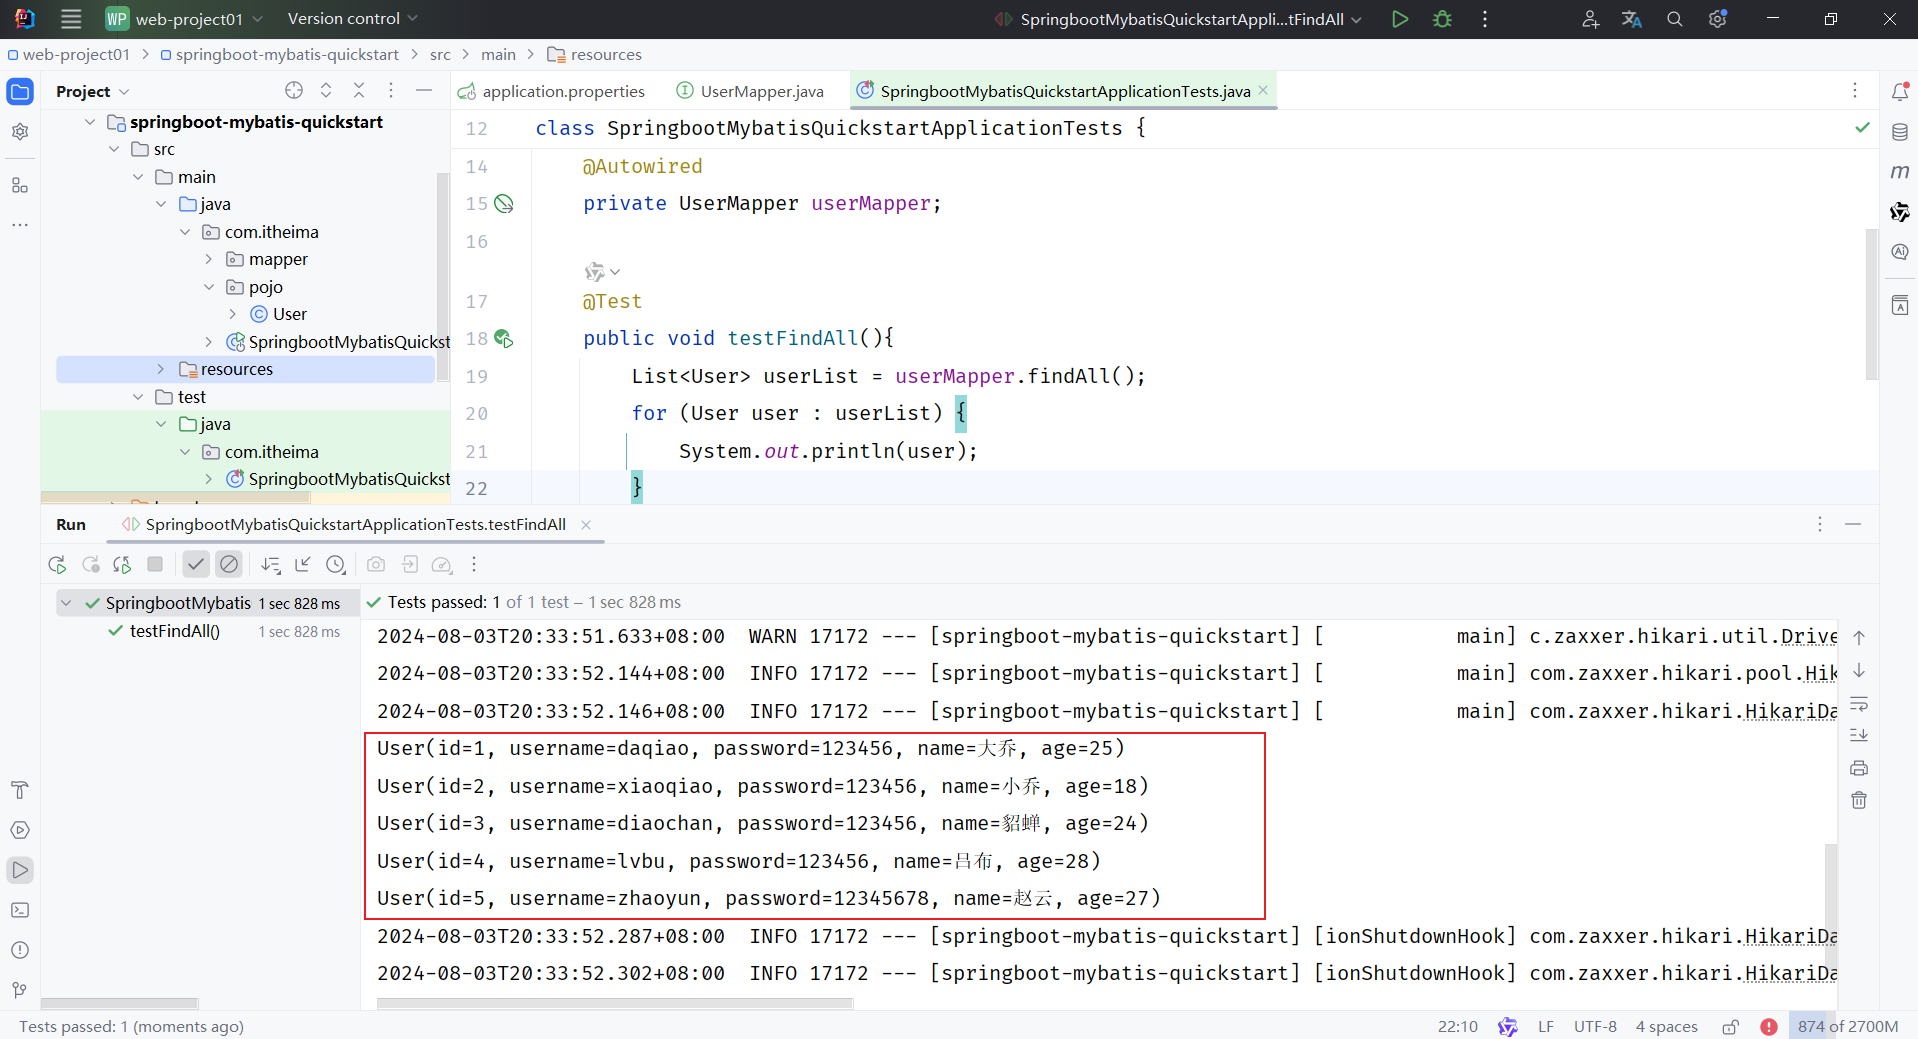

注意：测试类所在包，需要与引导类所在包相同。

> **勘误：**与引导类同包是最容易理解的放法，并非唯一合法位置。`@SpringBootTest` 通常向上搜索 `@SpringBootConfiguration`；测试放在引导类包或其子包一般可找到配置，也可以用 `classes = XxxApplication.class` 显式指定。Mapper 放在可扫描的包中并加 `@Mapper`；集中扫描时可在配置类使用 `@MapperScan`。


#### 3.1.2 辅助配置


##### 3.1.2.1 配置SQL提示

默认我们在UserMapper接口上加的 <code>@Select</code> 注解中编写SQL语句是没有提示的。 如果想让idea给我们提示对应的SQL语句，我们需要在IDEA中配置与MySQL数据库的链接。 

默认我们在UserMapper接口上的 <code>@Select</code> 注解中编写SQL语句是没有提示的。如果想让idea给出提示，可以做如下配置：

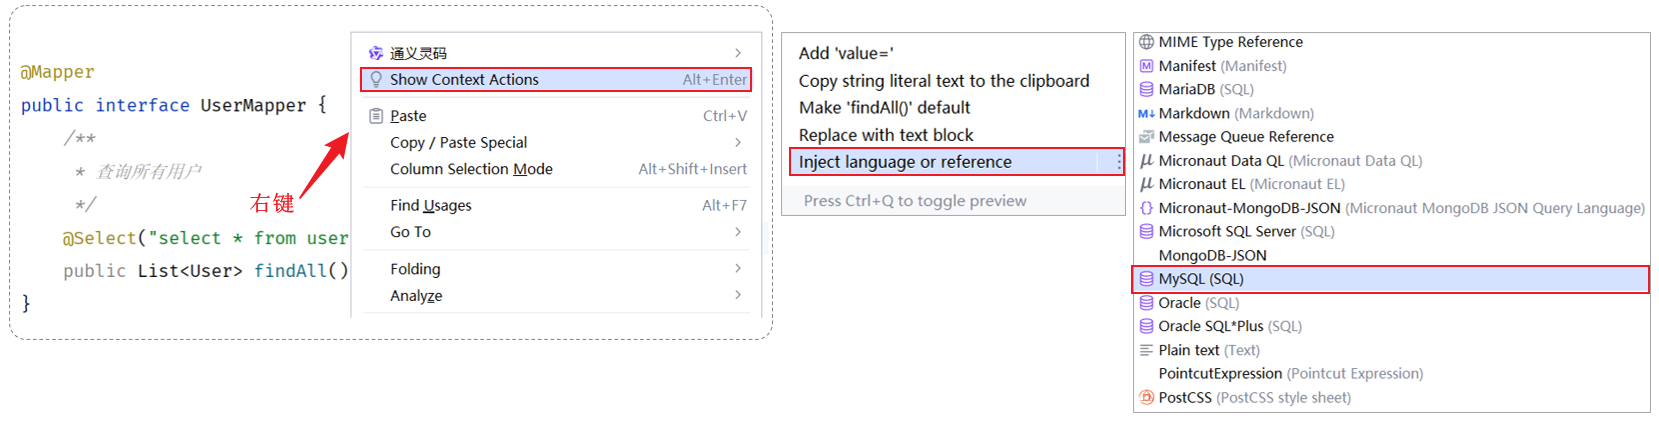

配置完成之后，发现SQL语句中的关键字有提示了，但还存在不识别表名(列名)的情况：

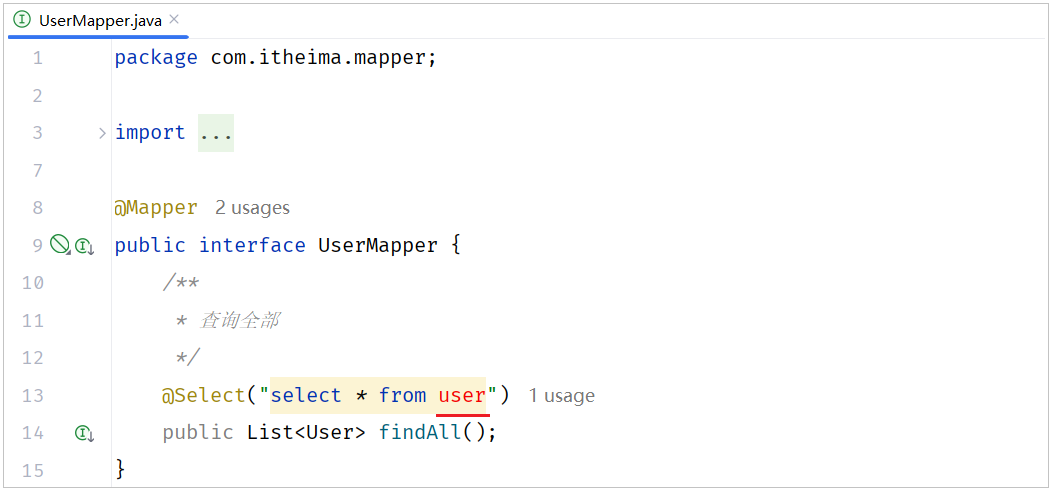

- 产生原因：Idea和数据库没有建立连接，不识别表信息
- 解决方案：在Idea中配置MySQL数据库连接

按照如下方如下方式，来配置当前IDEA关联的MySQL数据库（必须要指定连接的是哪个数据库）。

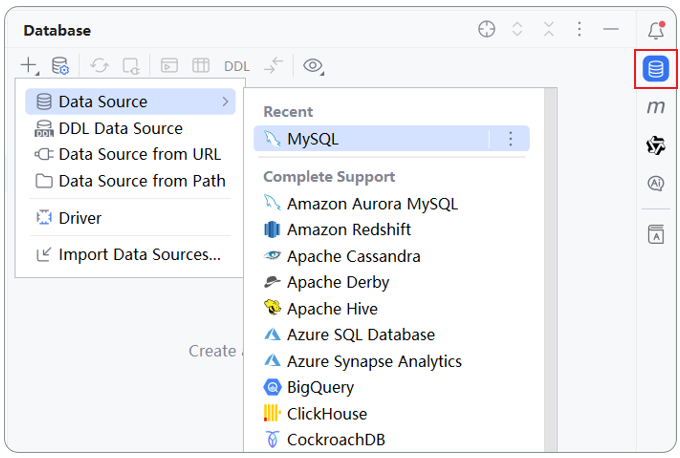

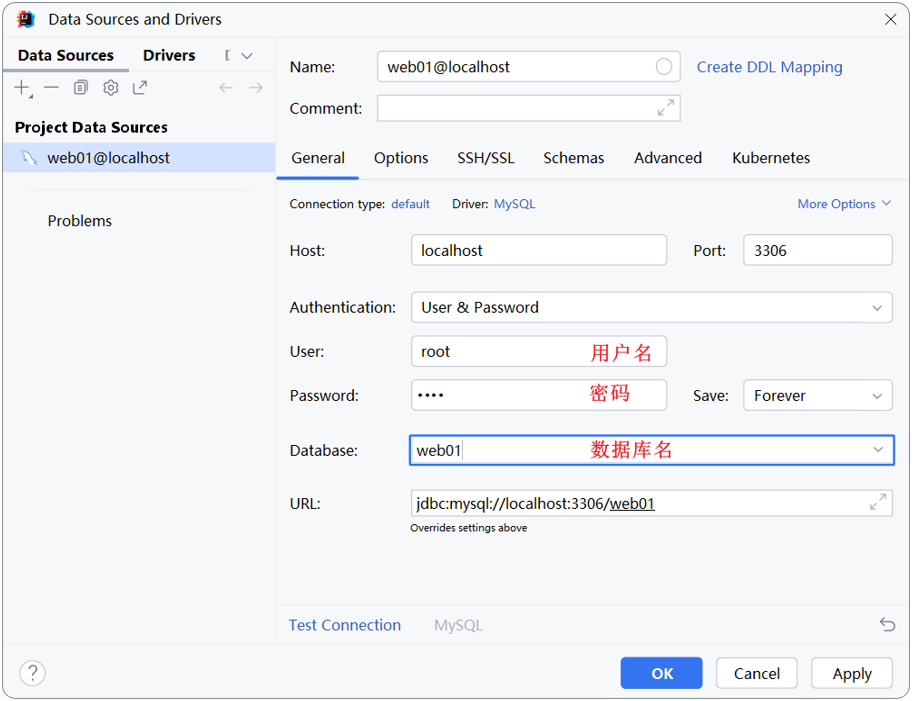

在配置的时候指定连接那个数据库，如上图所示连接的就是mybatis数据库（自己的数据库名是什么就指定什么）。

> <strong>注意：</strong>该配置的目的，仅仅是为了在编写SQL语句时，有语法提示（写错了会报错），不会影响运行，即使不配置也是可以的。


##### 3.1.2.2 配置Mybatis日志输出

默认情况下，在Mybatis中，SQL语句执行时，我们并看不到SQL语句的执行日志。 在<code>application.properties</code>加入如下配置，即可查看日志： 

````properties
#mybatis的配置
mybatis.configuration.log-impl=org.apache.ibatis.logging.stdout.StdOutImpl
````

> **读日志：**`Preparing` 查看带 `?` 的 SQL；`Parameters` 查看绑定值及类型；`Total` 或 `Updates` 查看结果数量。`StdOutImpl` 适合学习时观察，真实项目通常接入日志框架并控制级别；绑定参数可能包含密码等信息，不应直接保留在生产日志里。

打开上述开关之后，再次运行单元测试，就可以看到控制台输出的SQL语句是什么样子的。

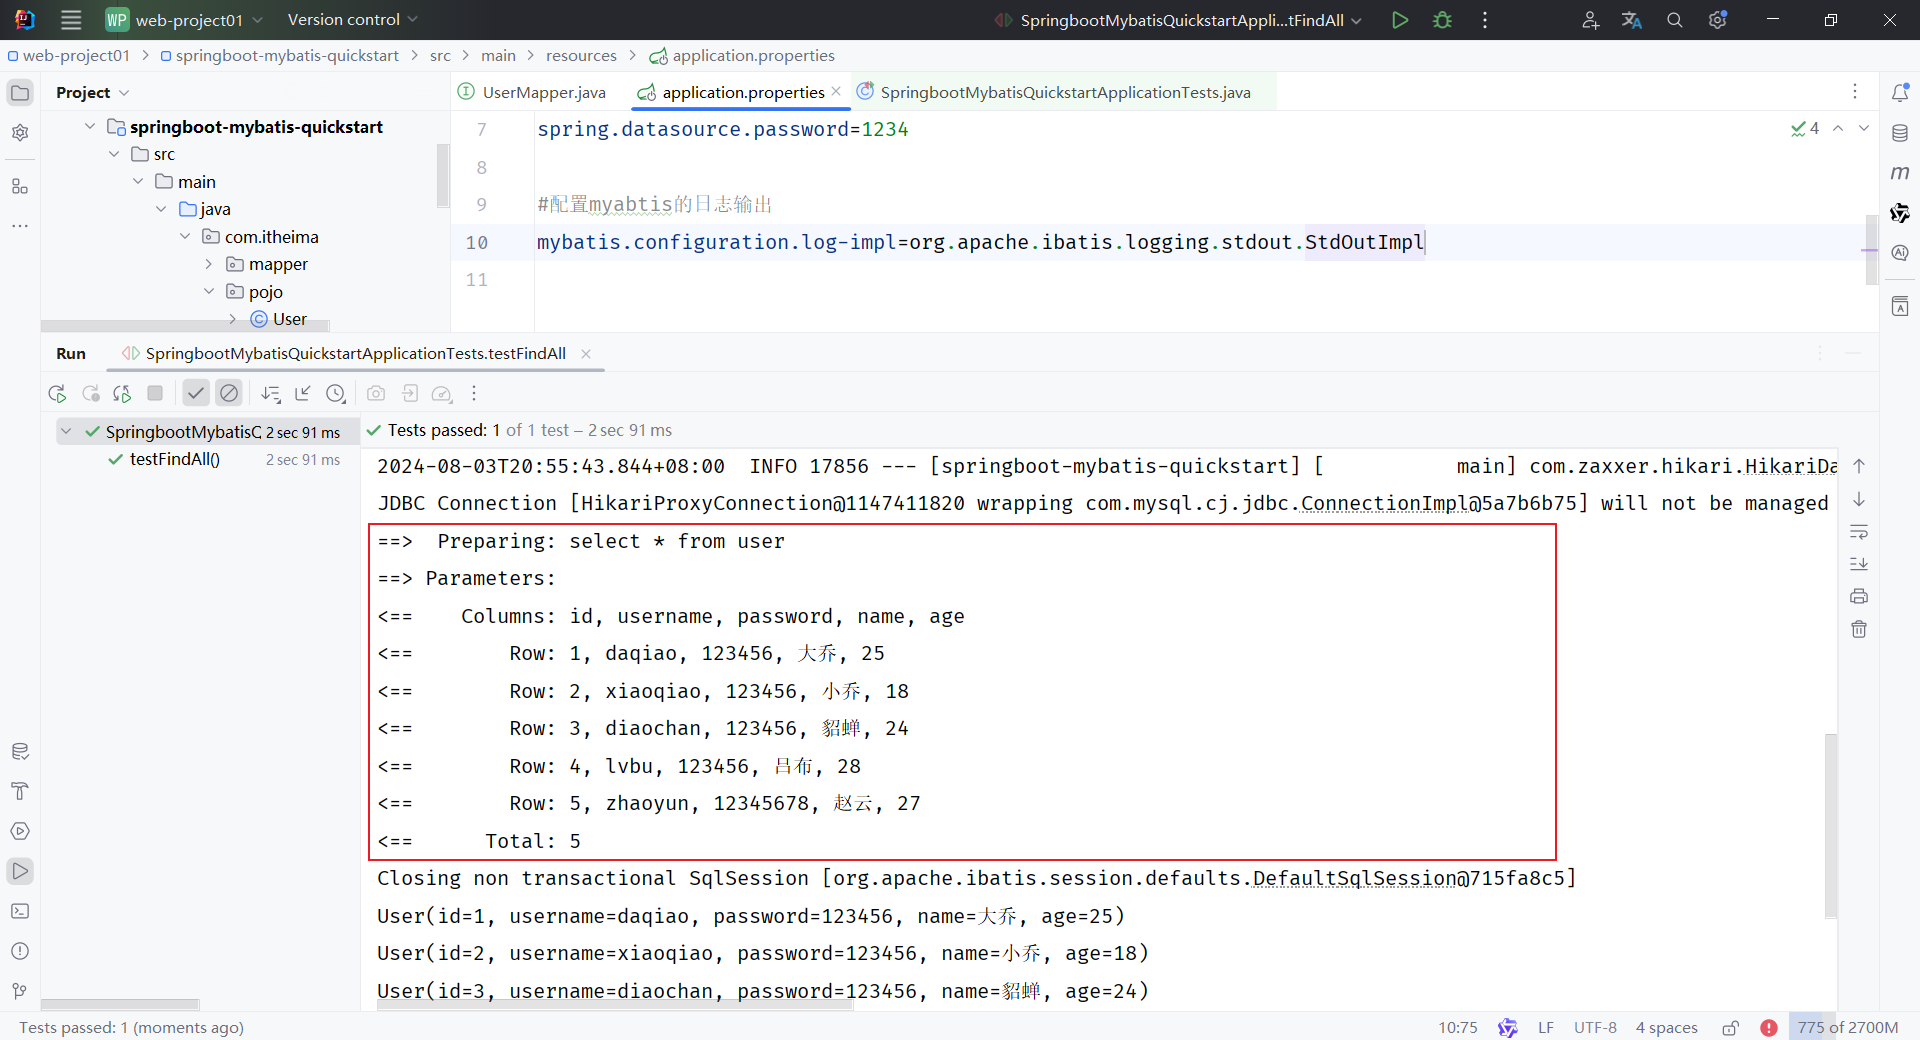


#### 3.1.3 JDBC VS  Mybatis

JDBC程序的<strong>缺点</strong>：

- url、username、password 等相关参数全部硬编码在java代码中。
- 查询结果的解析、封装比较繁琐。
- 每一次操作数据库之前，先获取连接，操作完毕之后，关闭连接。 频繁的获取连接、释放连接造成资源浪费。

分析了JDBC的缺点之后，我们再来看一下在mybatis中，是如何解决这些问题的：

- 数据库连接四要素(驱动、链接、用户名、密码)，都配置在springboot默认的配置文件 application.properties中
- 查询结果的解析及封装，由mybatis自动完成映射封装，我们无需关注
- 在mybatis中使用了数据库连接池技术，从而避免了频繁的创建连接、销毁连接而带来的资源浪费。

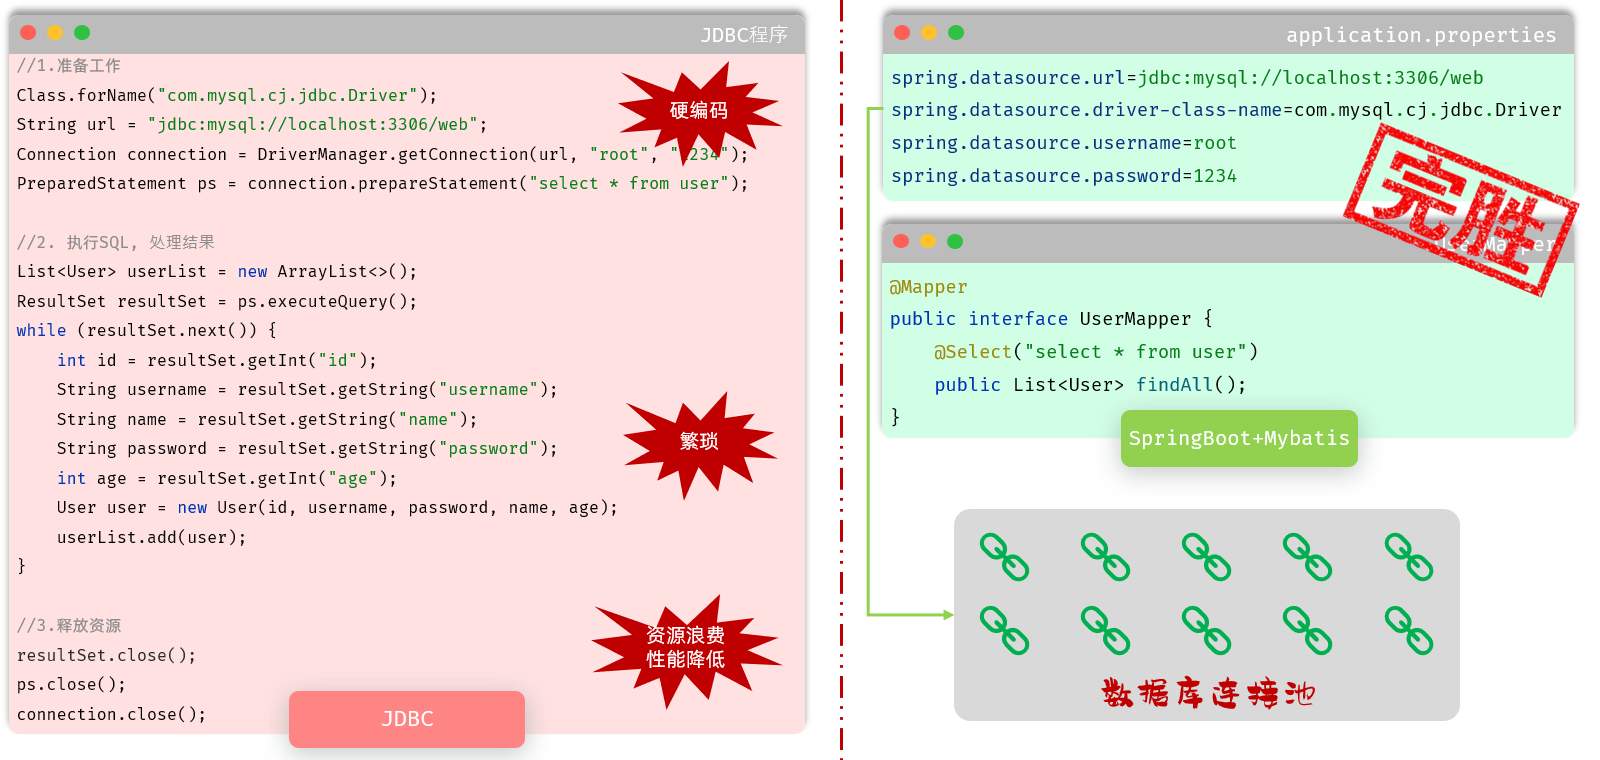

**理解修正：**硬编码和不使用连接池是这个原生 JDBC 示例的写法，不是 JDBC 的限制。JDBC 同样能从配置读取连接信息并通过 DataSource 取连接；MyBatis 帮你处理 SQL 执行、参数绑定和结果映射，Spring Boot 则负责许多自动配置。

| 工作 | 本章手写 JDBC | Spring Boot + MyBatis |
| --- | --- | --- |
| SQL、业务条件 | 开发者编写 | 仍由开发者编写 |
| 参数传递 | `setXxx(下标, 值)` | `#{名称}` + 参数对象 / `@Param` |
| 结果封装 | 遍历 ResultSet，逐字段赋值 | 按属性名/映射规则封装 |
| 资源管理 | 自己保证及时关闭 | 由 MyBatis-Spring 等组件协调 |
| 连接池 | 可通过 DataSource 使用 | 常见 starter 自动配置 HikariCP |

框架减少重复工作，但不会自动替你设计 SQL、索引或事务边界。

> 使用SpringBoot+Mybatis的方式操作数据库，能够提升开发效率、降低资源浪费

而对于Mybatis来说，我们在开发持久层程序操作数据库时，需要重点关注以下两个方面：

1. application.properties

````properties
#驱动类名称
spring.datasource.driver-class-name=com.mysql.cj.jdbc.Driver
#数据库连接的url
spring.datasource.url=jdbc:mysql://localhost:3306/web01
#连接数据库的用户名
spring.datasource.username=root
#连接数据库的密码
spring.datasource.password=1234
````

1. Mapper接口（编写SQL语句）

````java
@Mapper
public interface UserMapper {
    @Select("select * from user")
    public List<User> list();
}
````


#### 3.1.4 数据库连接池

在前面我们所讲解的mybatis中，使用了数据库连接池技术，避免频繁的创建连接、销毁连接而带来的资源浪费。

下面我们就具体的了解下数据库连接池。


##### 3.1.4.1 介绍

1). 没有数据库连接池的情况

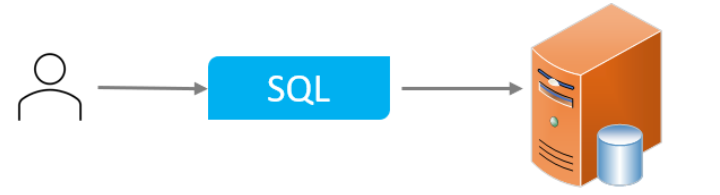

客户端执行SQL语句：要先创建一个新的连接对象，然后执行SQL语句，SQL语句执行后又需要关闭连接对象从而释放资源，每次执行SQL时都需要创建连接、销毁链接，这种频繁的重复创建销毁的过程是比较耗费计算机的性能。

2). 有数据库连接池的情况

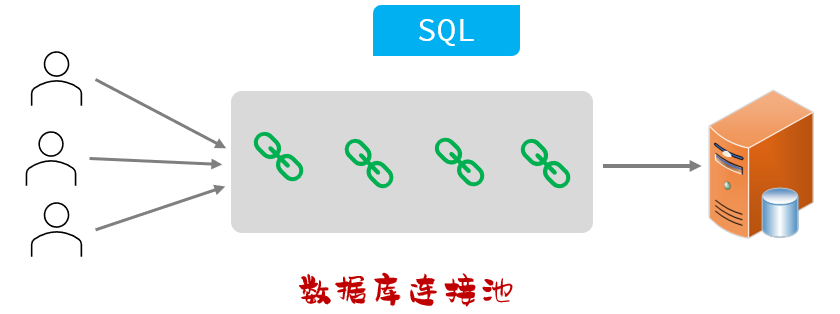

数据库连接池是个容器，负责分配、管理数据库连接(Connection)

- 程序在启动时，会在数据库连接池(容器)中，创建一定数量的Connection对象

允许应用程序重复使用一个现有的数据库连接，而不是再重新建立一个

- 客户端在执行SQL时，先从连接池中获取一个Connection对象，然后在执行SQL语句，SQL语句执行完之后，释放Connection时就会把Connection对象归还给连接池（Connection对象可以复用）

释放空闲时间超过最大空闲时间的连接，来避免因为没有释放连接而引起的数据库连接遗漏

- 客户端获取到Connection对象了，但是Connection对象并没有去访问数据库(处于空闲)，数据库连接池发现Connection对象的空闲时间 &gt; 连接池中预设的最大空闲时间，此时数据库连接池就会自动释放掉这个连接对象

> **连接池勘误：**池里的空闲连接与“已经借给业务代码、但业务代码暂时没发 SQL 的连接”不同。idleTimeout 通常清理池内空闲连接，不保证回收业务代码忘记关闭的连接。即使用连接池，也必须关闭借到的逻辑连接，将其归还；泄漏检测与自动回收能力取决于具体连接池和配置。池按需建立连接还是预先建立若干连接，同样取决于实现与配置。

数据库连接池的好处：

- 资源重用
- 提升系统响应速度
- 避免数据库连接遗漏


##### 3.1.4.2 产品

要怎么样实现数据库连接池呢？

- 官方(sun)提供了数据库连接池标准（javax.sql.DataSource接口）
- 功能：获取连接 

    ````java
    public Connection getConnection() throws SQLException;
    ````
- 第三方组织必须按照DataSource接口实现

常见的数据库连接池：<strong>C3P0 </strong><strong>、</strong><strong>DBCP </strong><strong>、</strong><strong>Druid </strong><strong>、</strong><strong>Hikari (springboot默认)</strong>

现在使用更多的是：<strong>Hikari、Druid  （性能更优越）</strong>

<strong>1). Hikari（追光者） &#91;默认的连接池&#93;</strong> 

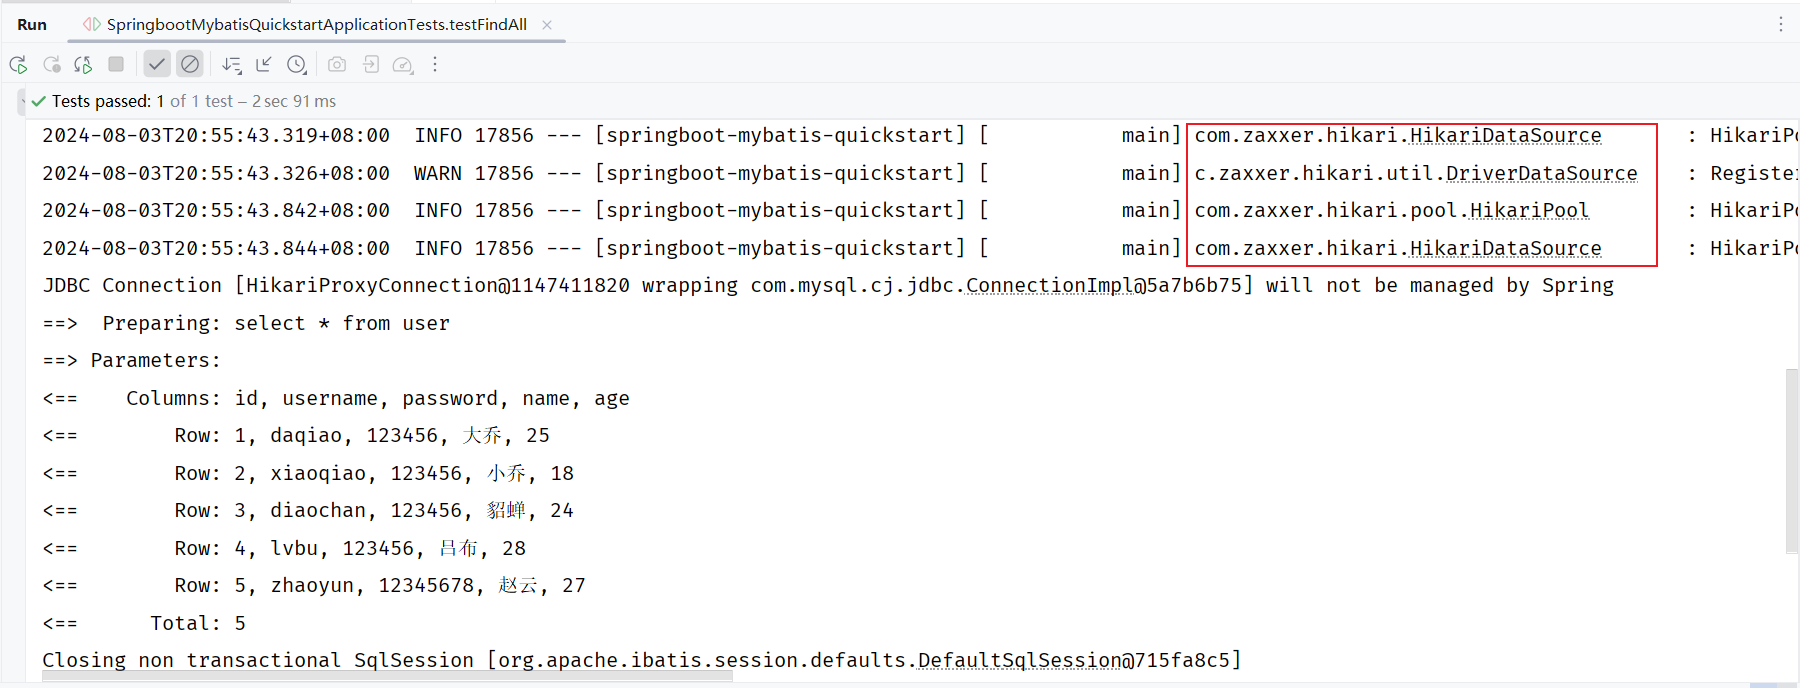

从控制台输出的日志，我们也可以看出，springboot底层默认使用的数据库连接池就是 Hikari。

> **补充：**本章常见的 Spring Boot JDBC/MyBatis starter 依赖带入 HikariCP，未手动指定其他 DataSource 时通常优先使用它。`javax.sql.DataSource` 是 JDK 标准接口，升级 Spring Boot 3 也不应改成不存在的 `jakarta.sql.DataSource`。

<strong>2). Druid（德鲁伊）</strong>

- Druid连接池是阿里巴巴开源的数据库连接池项目 
- 功能强大，性能优秀，是Java语言最好的数据库连接池之一

如果我们想把默认的数据库连接池切换为Druid数据库连接池，只需要完成以下两步操作即可：

> 参考官方地址：<a href="https://github.com/alibaba/druid/tree/master/druid-spring-boot-starter">https://github.com/alibaba/druid/tree/master/druid-spring-boot-starter</a>

①. 在<code>pom.xml</code>文件中引入依赖

````xml
<dependency>
    <!-- Druid连接池依赖 -->
    <groupId>com.alibaba</groupId>
    <artifactId>druid-spring-boot-starter</artifactId>
    <version>1.2.19</version>
</dependency>
````

**版本勘误：**上面是旧 starter。沿用 Spring Boot 3 时，参考 [Druid Spring Boot 3 官方说明](https://github.com/alibaba/druid/tree/master/druid-spring-boot-3-starter)，可选用其文档示例依赖：

```xml
<dependency>
    <groupId>com.alibaba</groupId>
    <artifactId>druid-spring-boot-3-starter</artifactId>
    <version>1.2.24</version>
</dependency>
```

这是与 Boot 3 对应的替换示例，不表示当前最新版本。先用默认 Hikari 完成 CRUD，再按需要换池；不要同时保留两个 Druid starter。数据库连接值仍以自己的环境为准。

②. 在<code>application.properties</code>中引入数据库连接配置

````properties
spring.datasource.type=com.alibaba.druid.pool.DruidDataSource
spring.datasource.druid.driver-class-name=com.mysql.cj.jdbc.Driver
spring.datasource.druid.url=jdbc:mysql://localhost:3306/web
spring.datasource.druid.username=root
spring.datasource.druid.password=1234
````

配置完毕之后，我们再次运行单元测试，大家会看到控制台输出的日志中，已经将连接池切换为了 Druid连接池。

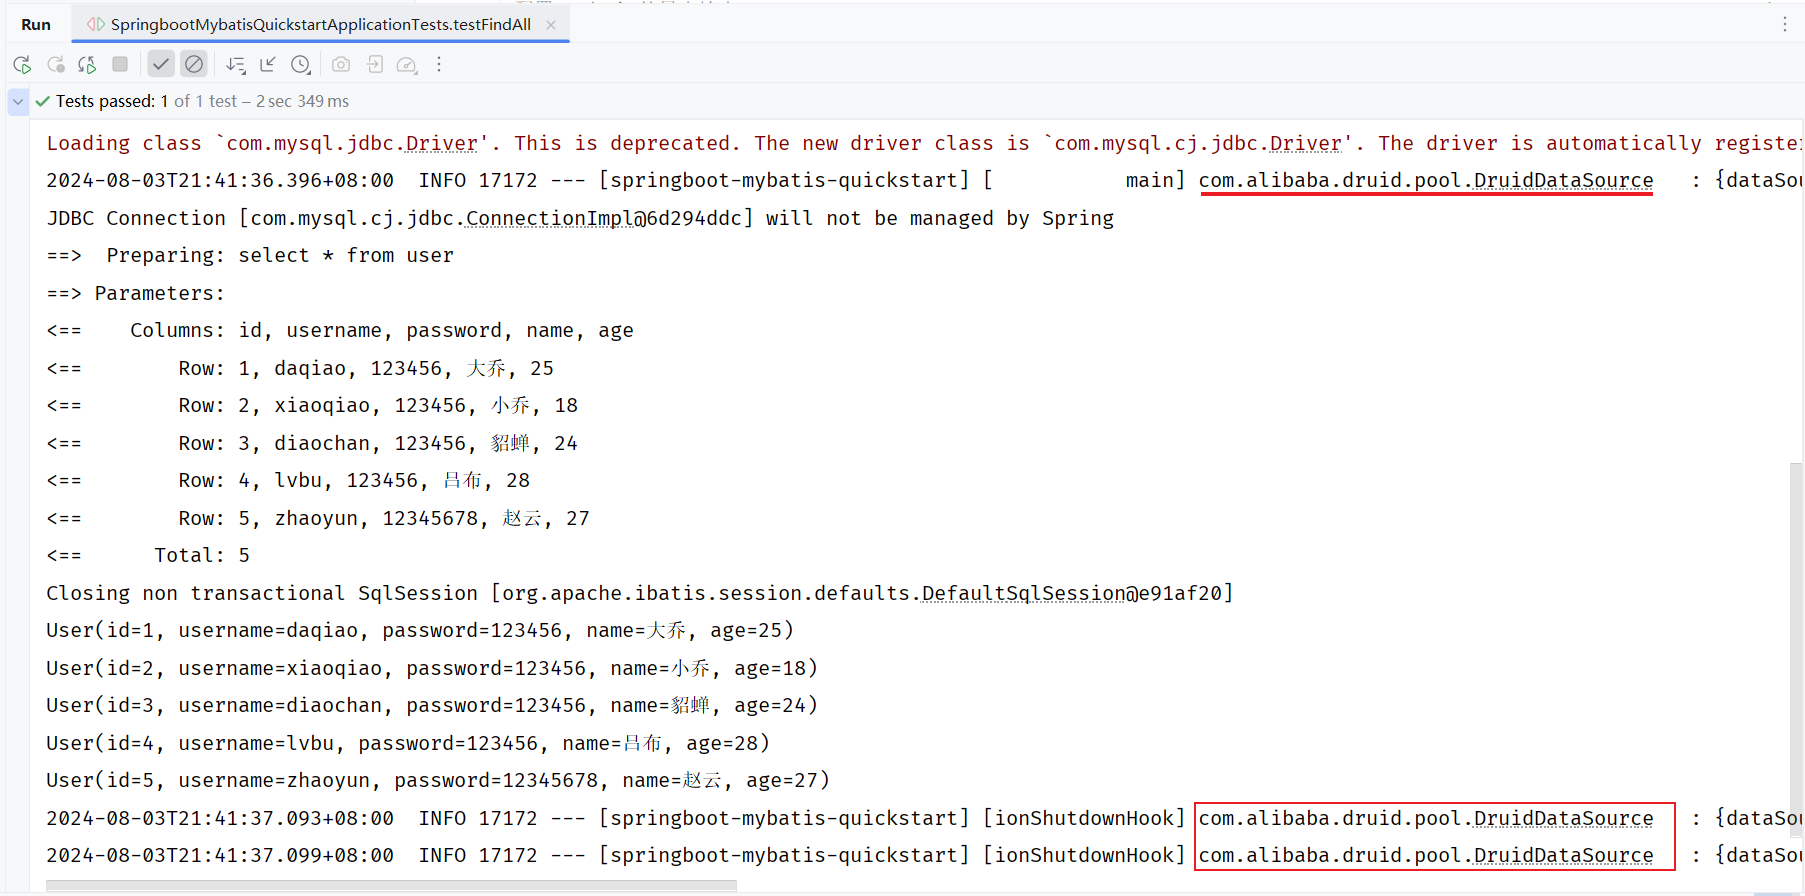


#### 3.1.5 增删改查操作


##### 3.1.5.1 删除

- 需求：根据ID删除用户信息
- SQL：delete from user where id = 5;
- Mapper接口方法：

    - 方式一：

    ````java
    /**
     * 根据id删除
     */
    @Delete("delete from user where id = 5")
    public void deleteById();
    ````

这种方式执行删除操作，调用deleteById方法只能删除id为5的用户信息，因为将id直接写死在代码中了，不可取。

- 方式二：

````java
/**
 * 根据id删除
 */
@Delete("delete from user where id = #{id}")
public void deleteById(Integer id);
````

在Mybatis中，我们可以通过参数占位符号 <code>&#35;{...}</code> 来占位，在调用<code>deleteById</code>方法时，传递的参数值，最终会替换占位符。

- 编写单元测试方法进行测试

    在单元测试类中,增加如下测试方法.

    ````java
    @Test
    public void testDeleteById(){
        userMapper.deleteById(36);
    }
    ````

    > **跟练提示：**初始数据只有 id=1～5，这里删除 id=36 通常返回 0；后文更新 id=6 也依赖前面确实插入过该记录。测试方法没有默认执行先后保证，不要靠“先运行新增测试”推测主键。第 5.5 节在同一个测试中插入、取得自增 id、查询、更新再删除。

运行单元测试，结果如下：

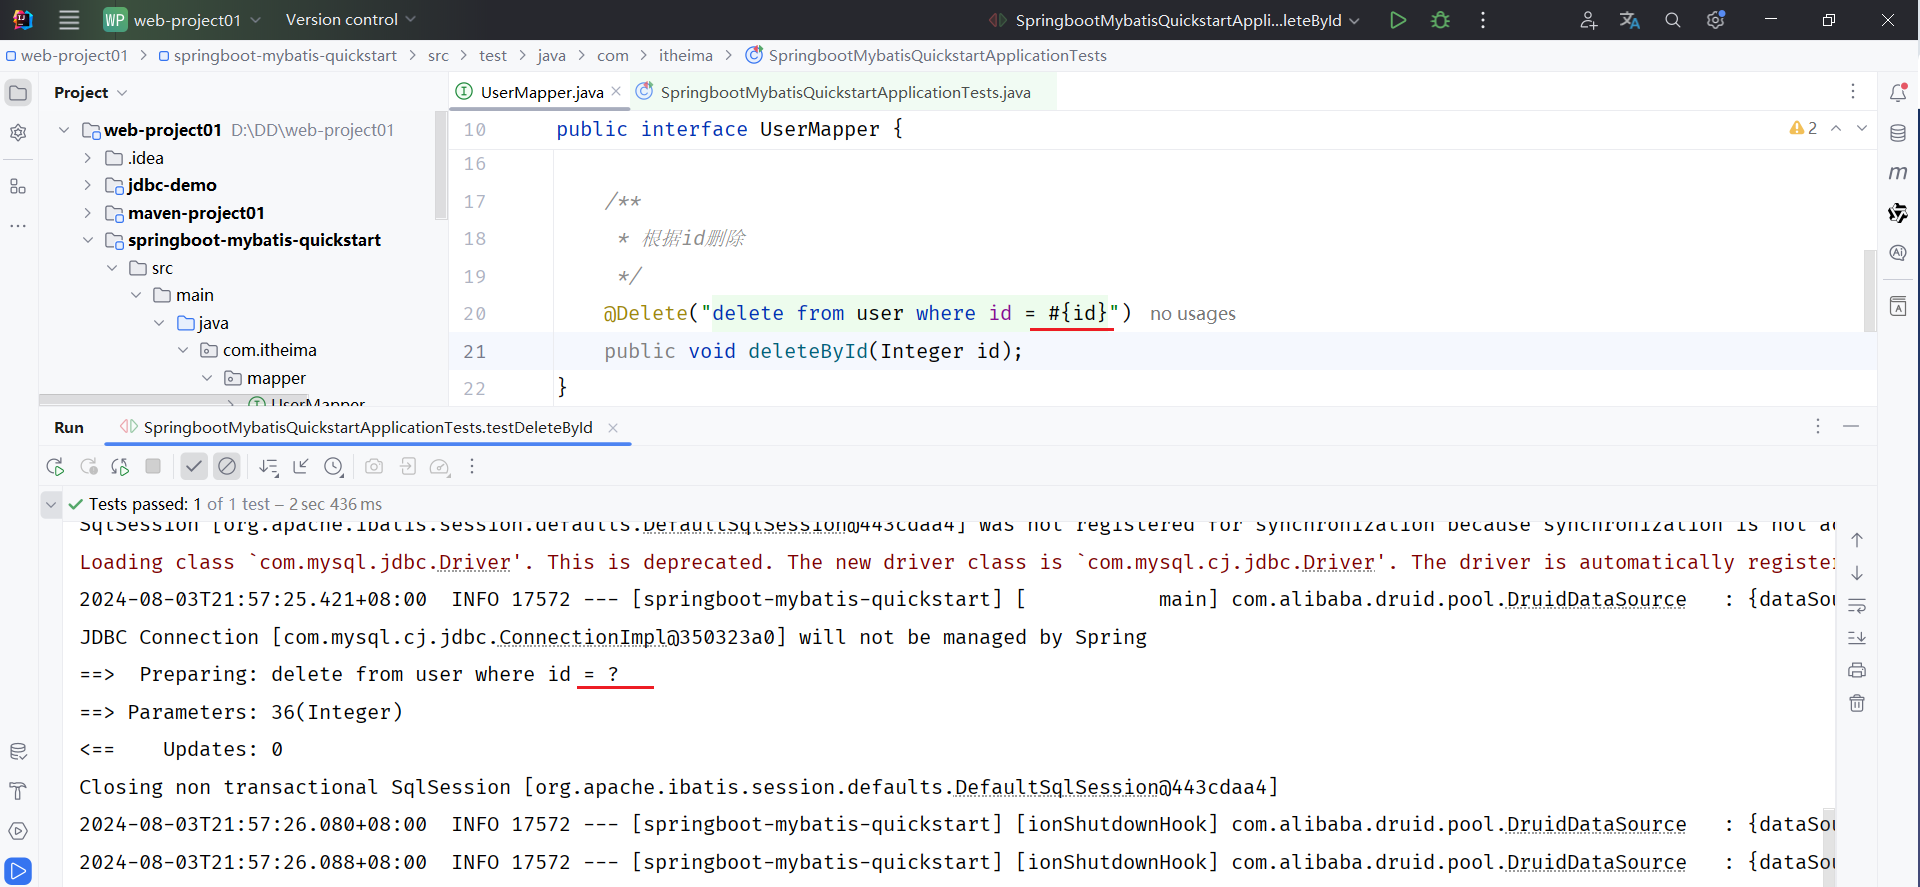

运行之后，我们发现，<code>&#35;{...}</code> 占位符，其实最终被替换成了 ？占位符，生成的是预编译的SQL语句。【推荐】

- DML语句执行完毕，是有返回值的，我们可以为Mapper接口方法定义返回值来接收，如下：

    ````java
    /**
     * 根据id删除
     */
    @Delete("delete from user where id = #{id}")
    public Integer deleteById(Integer id);
    ````

Integer类型的返回值，表示DML语句执行完毕影响的记录数。

- Mybatis的提供的符号，有两个，一个是 <code>&#35;{...}</code>，另一个是 <code>&#36;{...}</code>，区别如下：

| 符号 | 说明 | 场景 | 优缺点 |
| --- | --- | --- | --- |
| &#35;{…} | 占位符。执行时，会将&#35;{…}替换为?，生成预编译SQL | 参数值传递 | 安全、性能高 （推荐） |
| &#36;{…} | 拼接符。直接将参数拼接在SQL语句中，存在SQL注入问题 | 表名、字段名动态设置时使用 | 不安全、性能低 |

**表格补充与勘误：**`#{}` 用于绑定**值**，`${}` 在 SQL 交给 JDBC 前直接插入文本。安全性差异来自是否让输入参与 SQL 结构；性能不能仅凭这两个符号绝对判断。动态排序列不能写成 `ORDER BY #{column}` 来选择字段，那会变成一个值；确需动态列名时，在服务端把用户选项映射到有限的固定字段，或用 XML `<choose>` 选择预写好的 SQL，不能把前端字符串直接放进 `${}`。

<strong>那在企业项目开发中，</strong><strong>强烈建议使用 &#35;{...} </strong><strong>。</strong>


##### 3.1.5.2 新增

- 需求：添加一个用户
- SQL：insert into user(username,password,name,age) values('zhouyu','123456','周瑜',20);
- Mapper接口：

````java
/**
 * 添加用户
 */
@Insert("insert into user(username,password,name,age) values(#{username},#{password},#{name},#{age})")
public void insert(User user);
````

> **补充：**单个普通对象参数可以直接写 `#{username}` 读取属性；若参数标了 `@Param("user")`，则写 `#{user.username}`。插入成功不代表 Java 对象的 id 自动有值，MySQL 自增主键回填可用 `@Options(useGeneratedKeys = true, keyProperty = "id")`；返回的 int 是行数，`user.getId()` 才是回填的主键。

如果在SQL语句中，我们需要传递多个参数，我们可以把多个参数封装到一个对象中。然后在SQL语句中，我们可以通过<code>&#35;{对象</code><code>属性</code><code>名}</code>的方式，获取到对象中封装的属性值。

- 单元测试：

在测试类中添加测试方法，代码如下：

````java
@Test
public void testInsert(){
    User user = new User();
    user.setUsername("admin");
    user.setPassword("123456");
    user.setName("管理员");
    user.setAge(30);
    userMapper.insert(user);
}
````

运行结果如下：

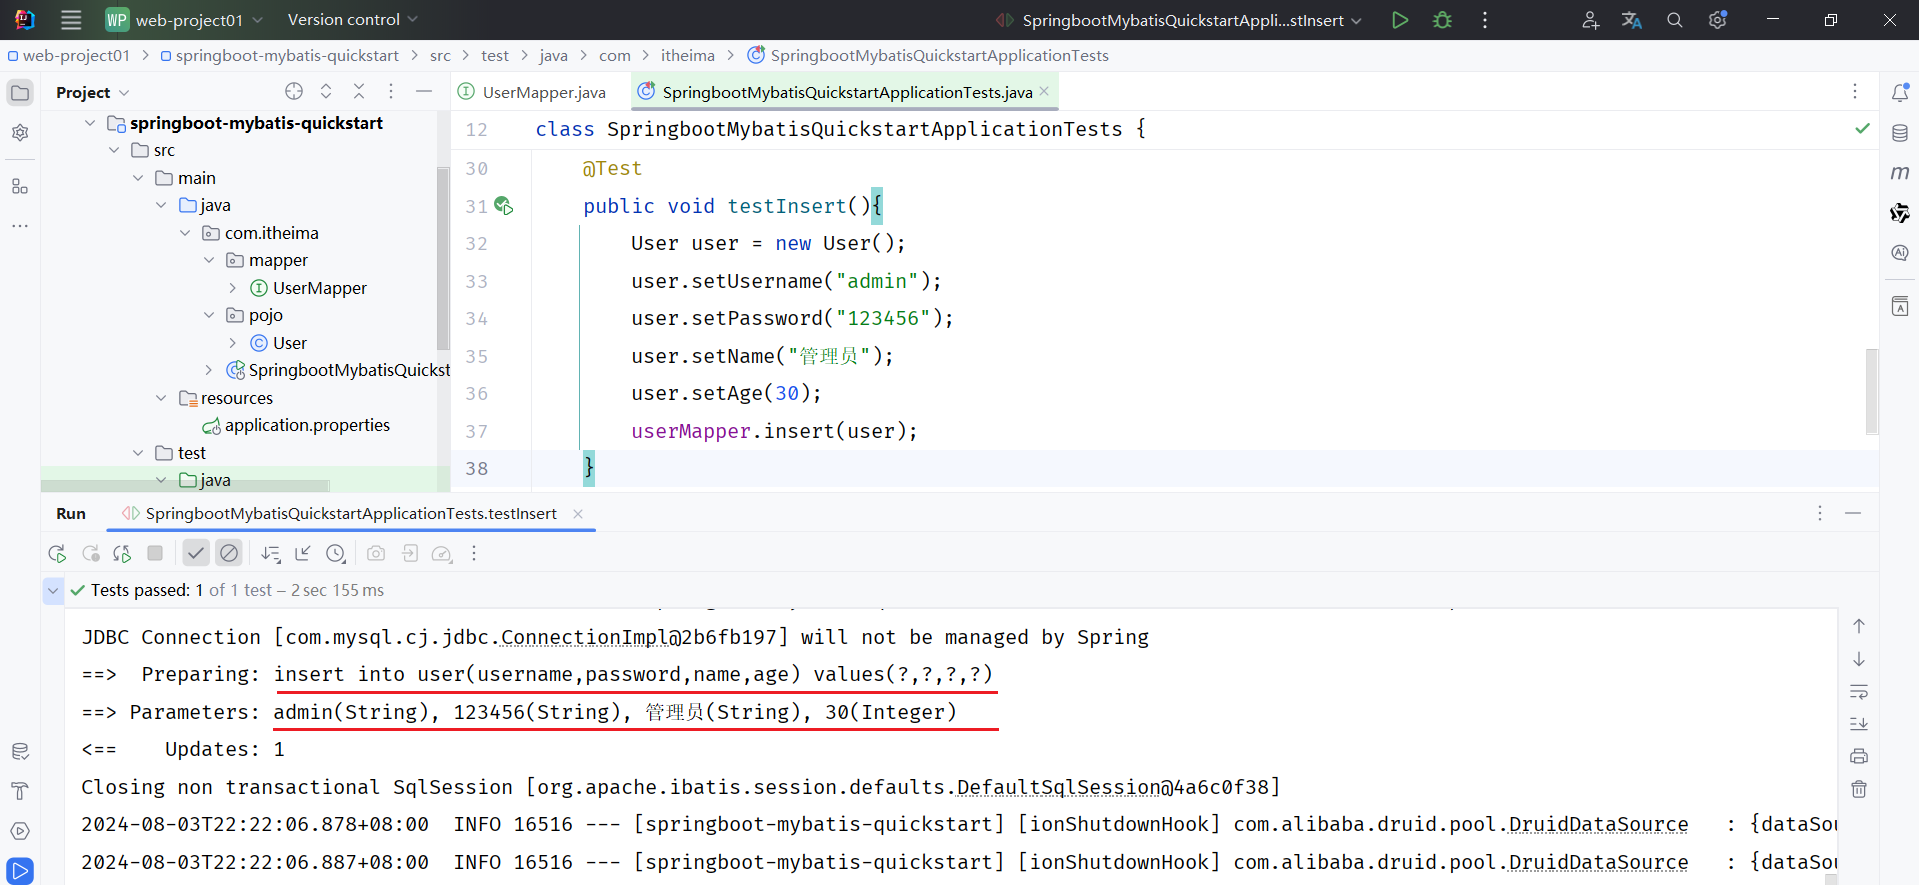


##### 3.1.5.3 修改

- 需求：根据ID更新用户信息
- SQL：update user set username = 'zhouyu', password = '123456', name = '周瑜', age = 20 where id = 1；

> **勘误：**句末的中文 `；` 不能直接放入 SQL 客户端执行，改成半角 `;`。更新条件仍要以实际存在的主键为准。
- Mapper接口方法：

````java
/**
 * 根据id更新用户信息
 */
@Update("update user set username = #{username},password = #{password},name = #{name},age = #{age} where id = #{id}")
public void update(User user);
````

- 单元测试：

在测试类中添加测试方法，代码如下：

````java
@Test
public void testUpdate(){
    User user = new User();
    user.setId(6);
    user.setUsername("admin666");
    user.setPassword("123456");
    user.setName("管理员");
    user.setAge(30);
    userMapper.update(user);
}
````

运行结果如下：

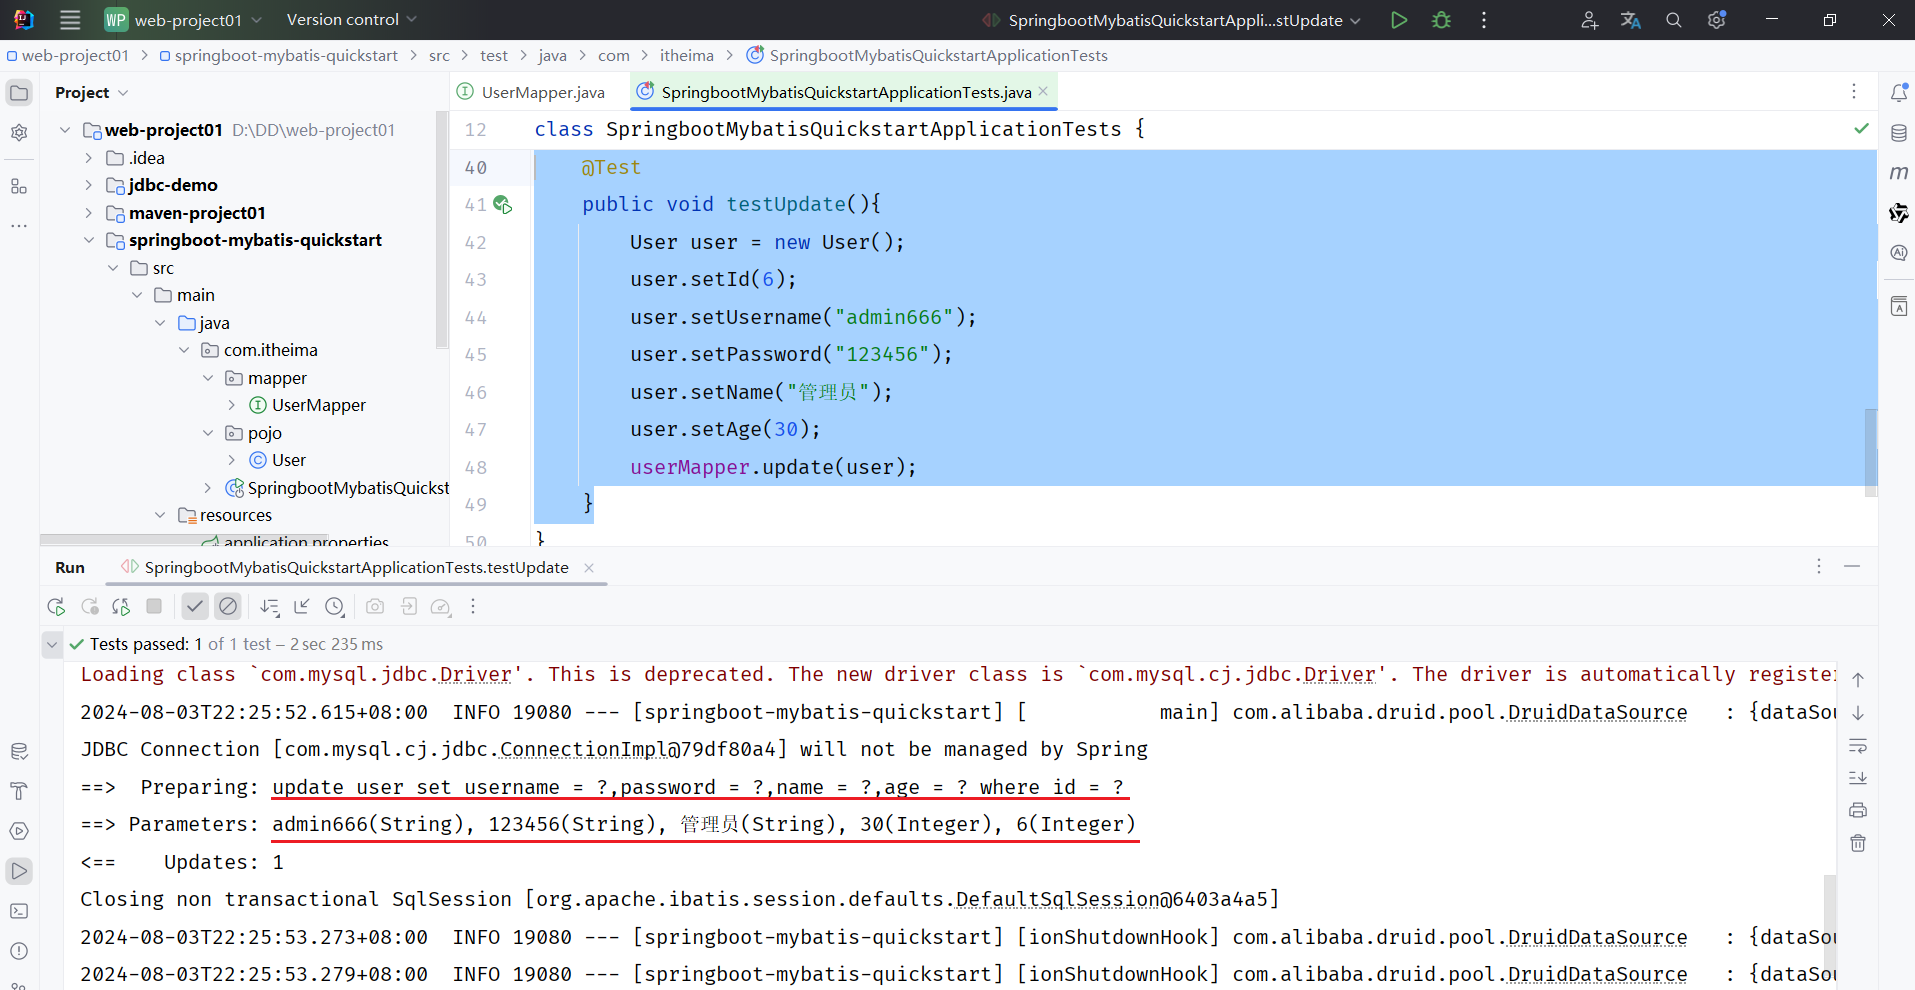


##### 3.1.5.4 查询

- 需求：根据用户名和密码查询用户信息
- SQL：select&#42;<em> </em>fromuser whereusername = 'zhouyu' and password = '123456'

> **排版勘误：**SQL 关键字与表名、列名之间需要空格：`SELECT * FROM user WHERE username = 'zhouyu' AND password = '123456';`。
- Mapper接口方法：

````java
/**
 * 根据用户名和密码查询用户信息
 */
@Select("select * from user where username = #{username} and password = #{password}")
public User findByUsernameAndPassword(@Param("username") String username, @Param("password") String password);
````

@param注解的作用是为接口的方法形参起名字的。（由于用户名唯一的，所以查询返回的结果最多只有一个，可以直接封装到一个对象中）

> **勘误：**注解名是 `@Param`，来自 `org.apache.ibatis.annotations.Param`。原表的 username 并没有 UNIQUE 约束，所以“用户名唯一”只是业务设想，数据库并未保证；返回单个 User 时，0 行通常得到 null，超过 1 行会抛 `TooManyResultsException`。应通过唯一约束确保唯一性，或按业务返回集合，不能靠 LIMIT 1 掩盖脏数据。
>
> **参数命名：**即使某些骨架启用了编译参数名保留，也建议多参数方法显式加 `@Param`，避免更换构建方式后出现 `Parameter ... not found`。

- 单元测试：

在测试类中添加测试方法，代码如下：

````java
@Test
public void testFindByUsernameAndPassword(){
    User user = userMapper.findByUsernameAndPassword("admin666", "123456");
    System.out.println(user);
}
````

运行结果如下：

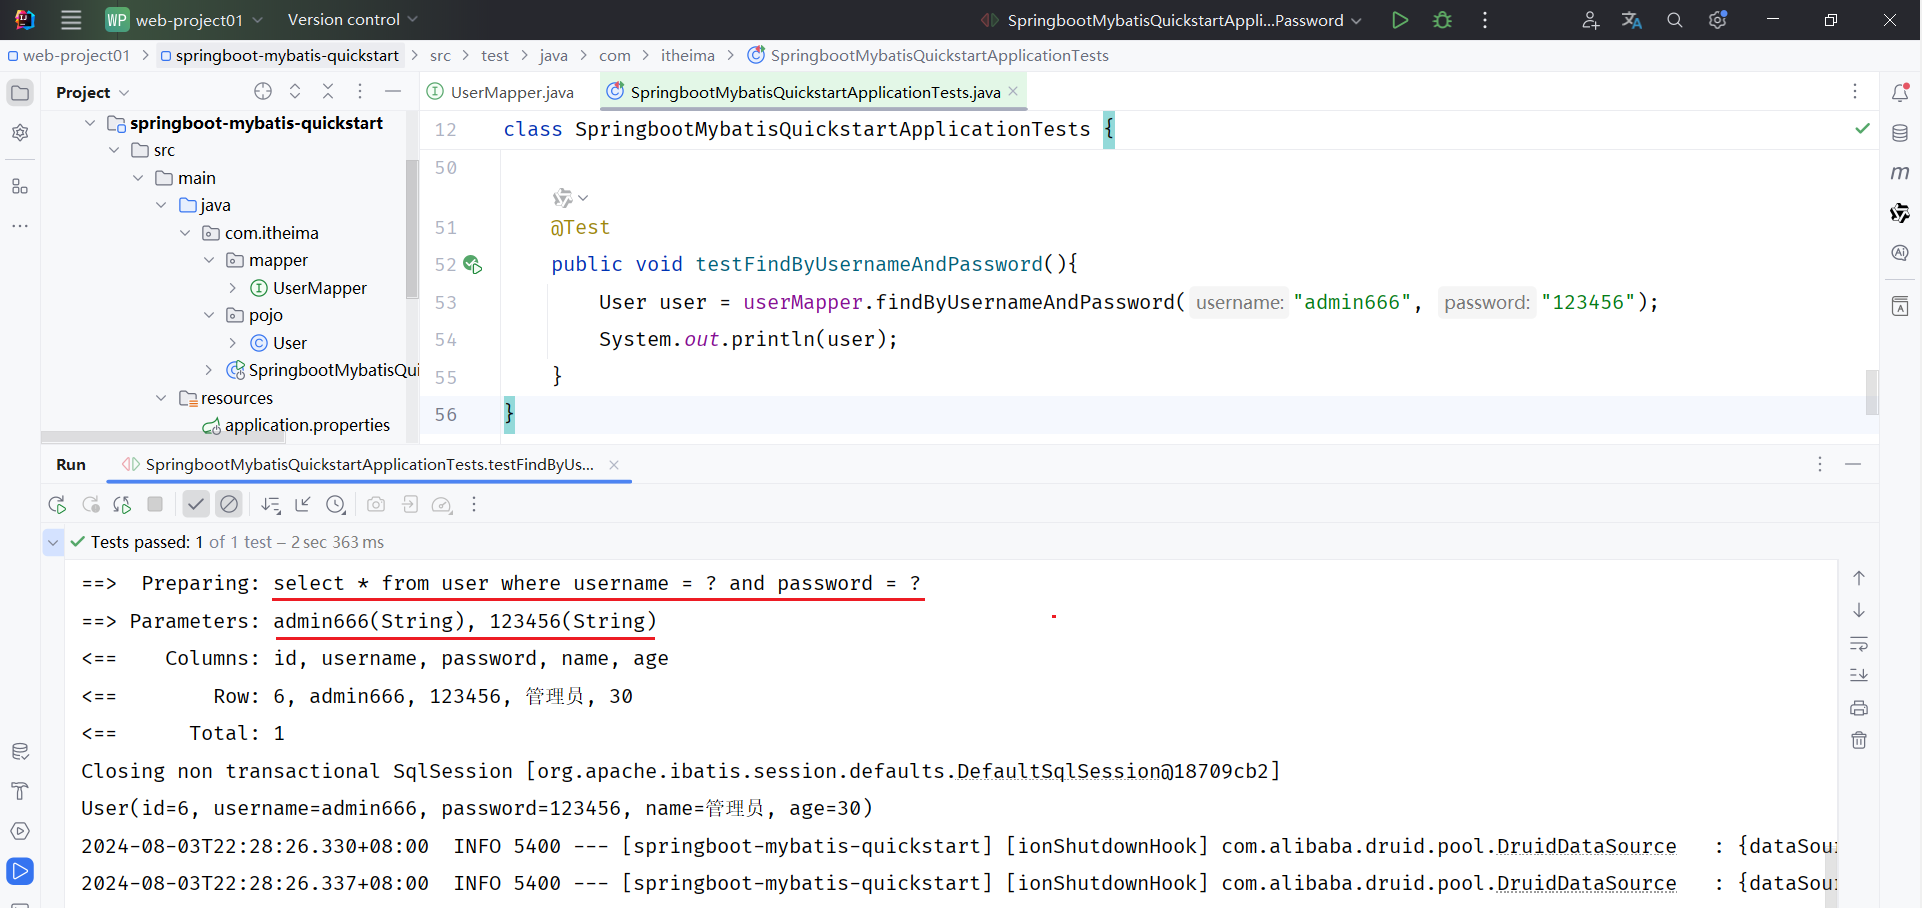

> <strong>说明：</strong>基于官方骨架创建的springboot项目中，接口编译时会保留方法形参名，@Param注解可以省略 (&#35;{形参名})。

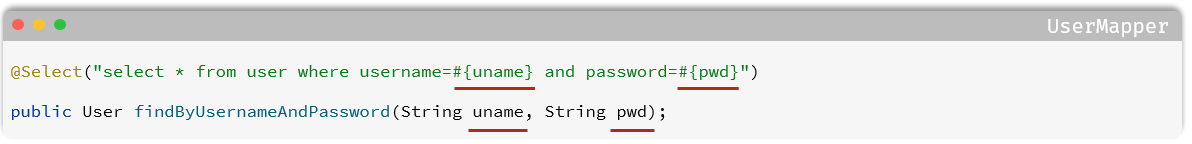


#### 3.1.6 XML映射配置

Mybatis的开发有两种方式：

1. 注解
2. XML


##### 3.1.6.1 XML配置文件规范

使用Mybatis的注解方式，主要是来完成一些简单的增删改查功能。如果需要实现复杂的SQL功能，建议使用XML来配置映射语句，也就是将SQL语句写在XML配置文件中。

> <strong>在Mybatis中使用XML映射文件方式开发，</strong><strong>需要符合一定的规范</strong><strong>：</strong>
> 
> 1. XML映射文件的名称与Mapper接口名称一致，并且将XML映射文件和Mapper接口放置在相同包下（同包同名）
> 
> > **规范说明：**“同包同名”是课程采用的常见自动发现方式，不是 XML 必须放在 Java 源码目录。推荐放在 `src/main/resources/com/itheima/mapper/UserMapper.xml`，构建后与接口形成对应类路径；也可以放在 `resources/mapper/` 并配置 `mybatis.mapper-locations`，这时文件名主要是约定。真正需要匹配的是 namespace、方法 id、参数及结果映射，而且文件必须被加载。普通 Maven 构建不会默认复制 `src/main/java` 下的 XML。
> 2. XML映射文件的namespace属性为Mapper接口全限定名一致
> 3. XML映射文件中sql语句的id与Mapper接口中的方法名一致，并保持返回类型一致。

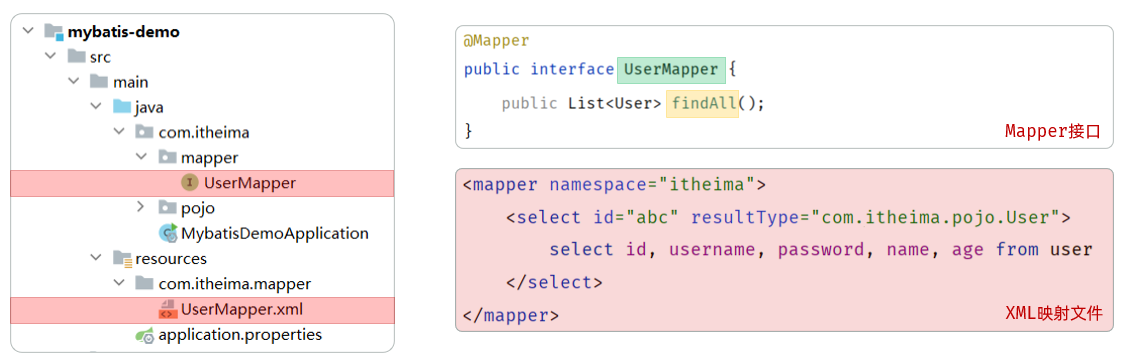

> &lt;select&gt;标签：就是用于编写select查询语句的。
> 
> - resultType属性，指的是查询返回的单条记录所封装的类型。


##### 3.1.6.2 XML配置文件实现

<strong>第1步： 创建XML映射文件</strong>

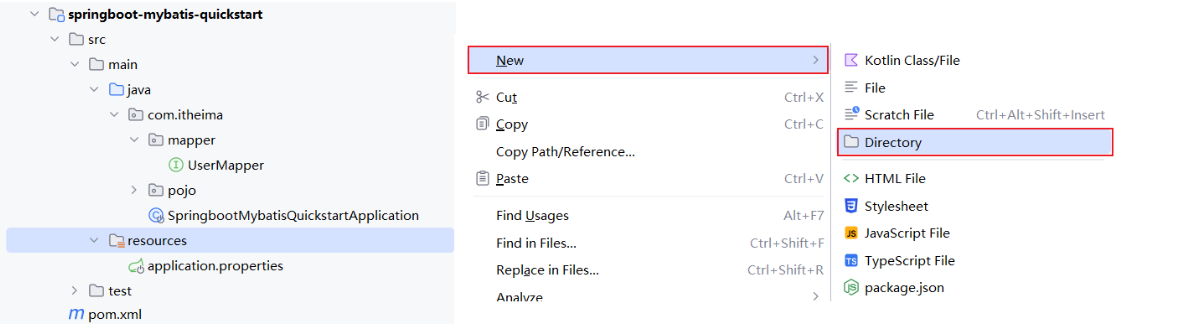

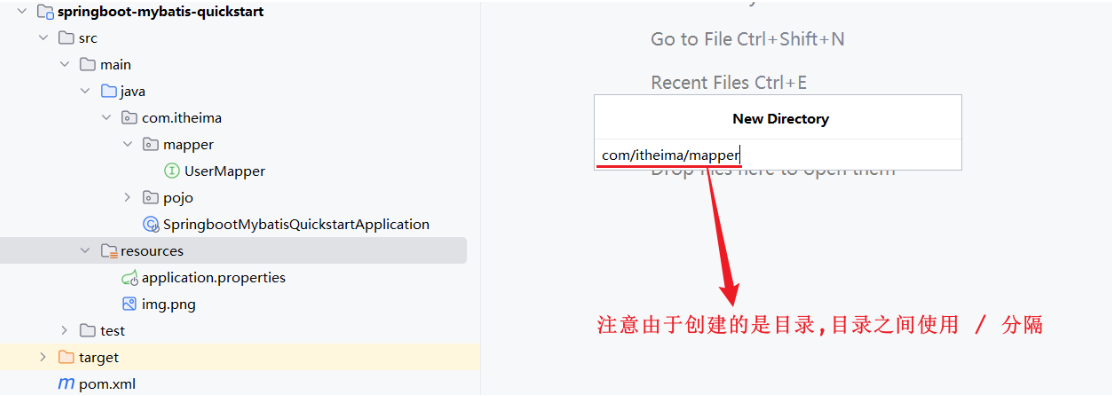

<strong>第2步：编写XML映射文件</strong>

> xml映射文件中的dtd约束，直接从mybatis官网复制即可; 或者直接AI生成。

````xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper
  PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
  "https://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="">
 
</mapper>
````

<strong>第3步：配置</strong>

<strong>a. XML映射文件的namespace属性为Mapper接口全限定名</strong>

````xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "https://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.UserMapper">

</mapper>
````

<strong>b. XML映射文件中sql语句的id与Mapper接口中的方法名一致，并保持返回类型一致</strong>

````xml
<?xml version="1.0" encoding="UTF-8" ?>
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "https://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.EmpMapper">

    <!--查询操作-->
    <select id="findAll" resultType="com.itheima.pojo.User">
        select * from user
    </select>
    
</mapper>
````

**勘误：**上面的 `namespace="com.itheima.mapper.EmpMapper"` 应改为 `com.itheima.mapper.UserMapper`，与本章接口对应。`findAll` 返回 `List<User>`，但 `resultType` 写的是单条结果类型 `com.itheima.pojo.User`，不是 List。迁移 findAll 到 XML 后，应移除该方法上的 `@Select`，否则同一个 statement 重复定义；其余方法仍可继续使用注解。

resultType 属性的值，与查询返回的单条记录封装的类型一致。

运行测试类，执行结果：

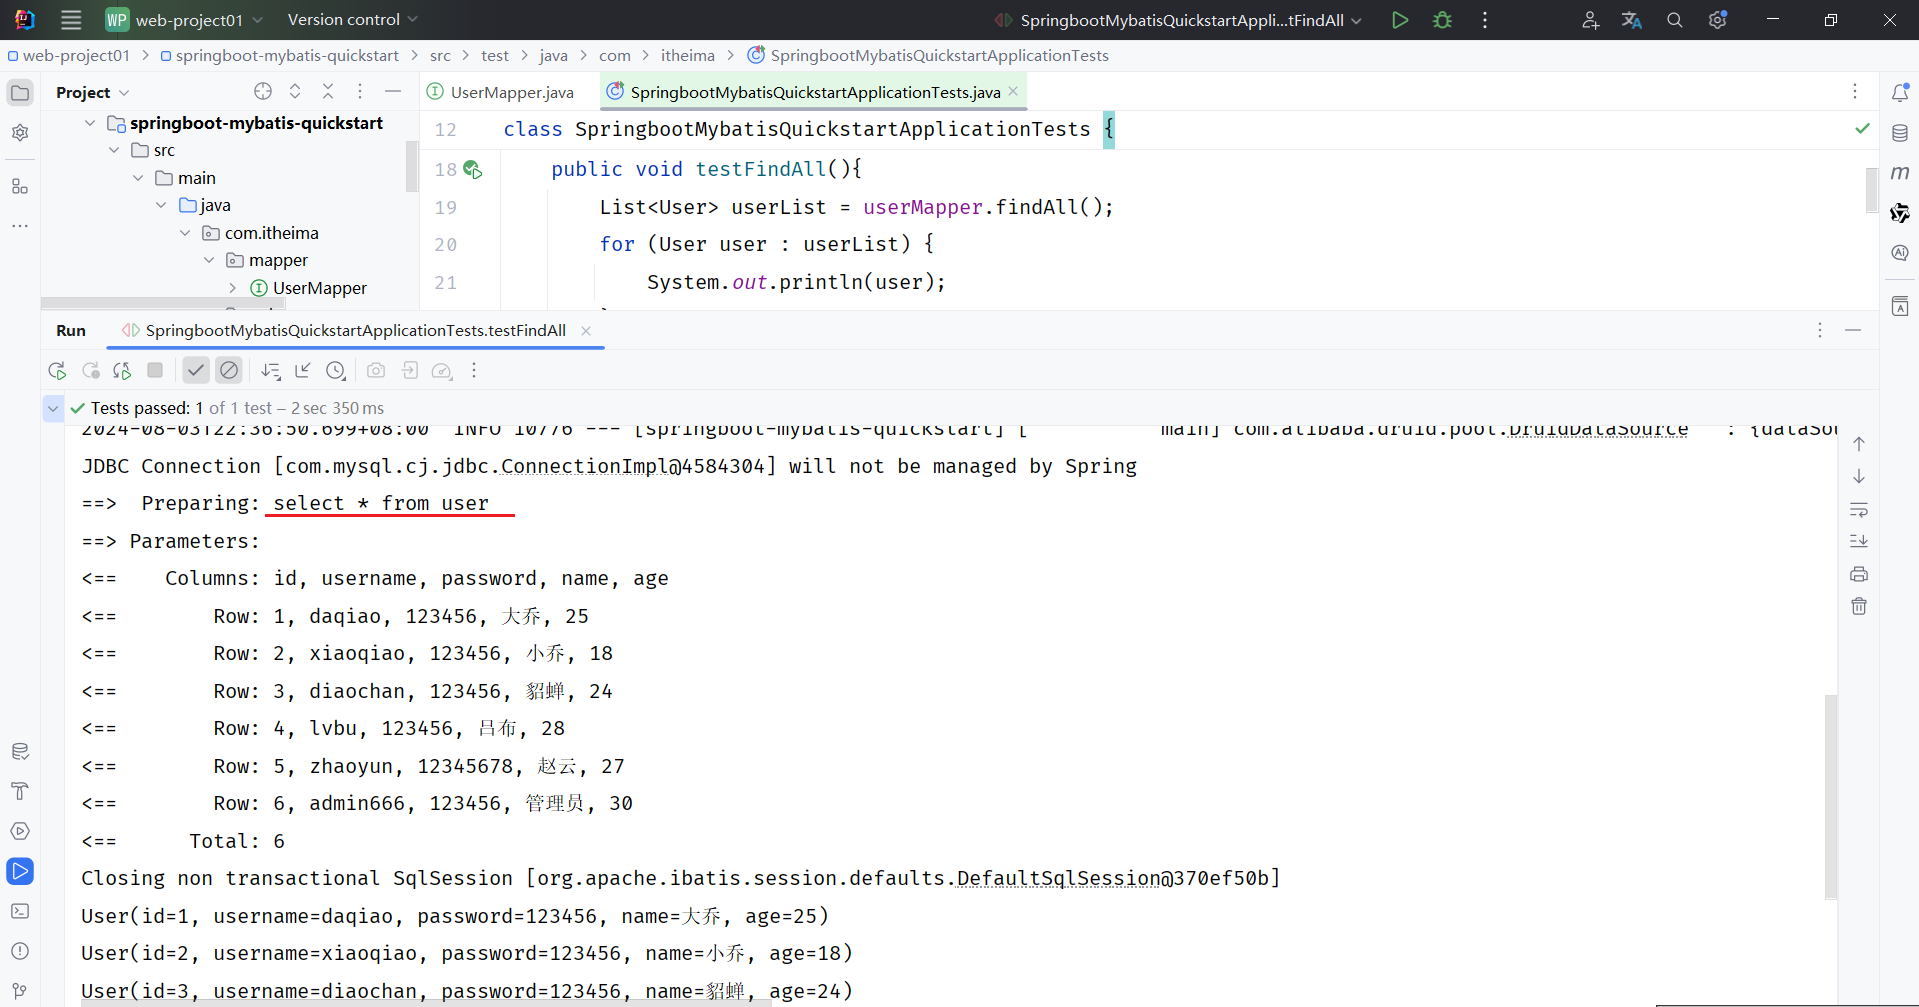

> <strong>注意</strong><strong>：一个接口方法对应的SQL语句，要么使用注解配置，要么使用XML配置，切不可同时配置。</strong>


##### 3.1.6.3 MybatisX的使用

MybatisX是一款基于IDEA的快速开发Mybatis的插件，为效率而生。

MybatisX的安装：

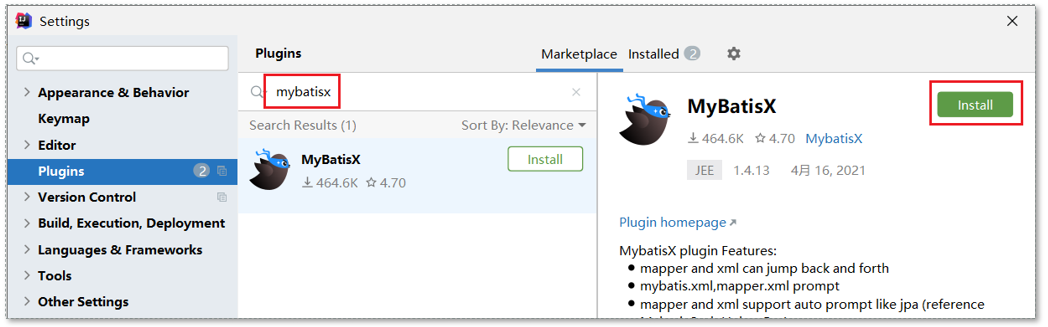

可以通过MybatisX快速定位：

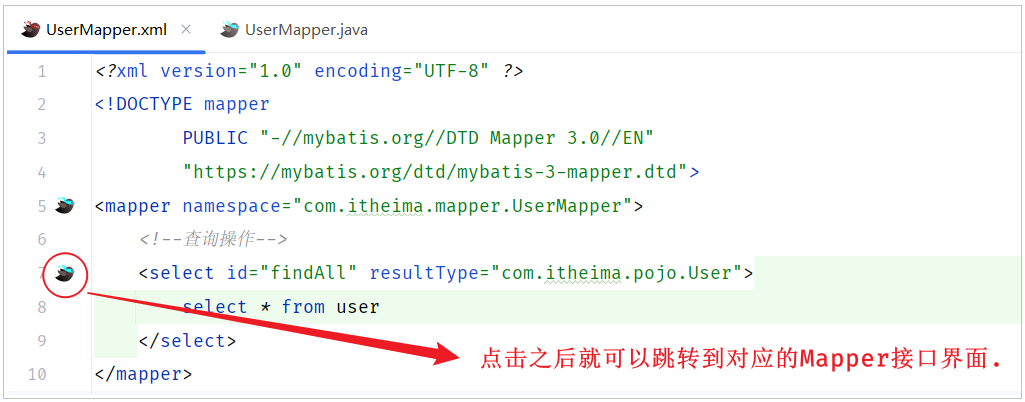

MybatisX的使用在后续学习中会继续分享。

> - 学习了Mybatis中XML配置文件的开发方式了，大家可能会存在一个疑问：到底是使用注解方式开发还是使用XML方式开发？

官方说明：https://mybatis.net.cn/getting-started.html。下面是官方说明:

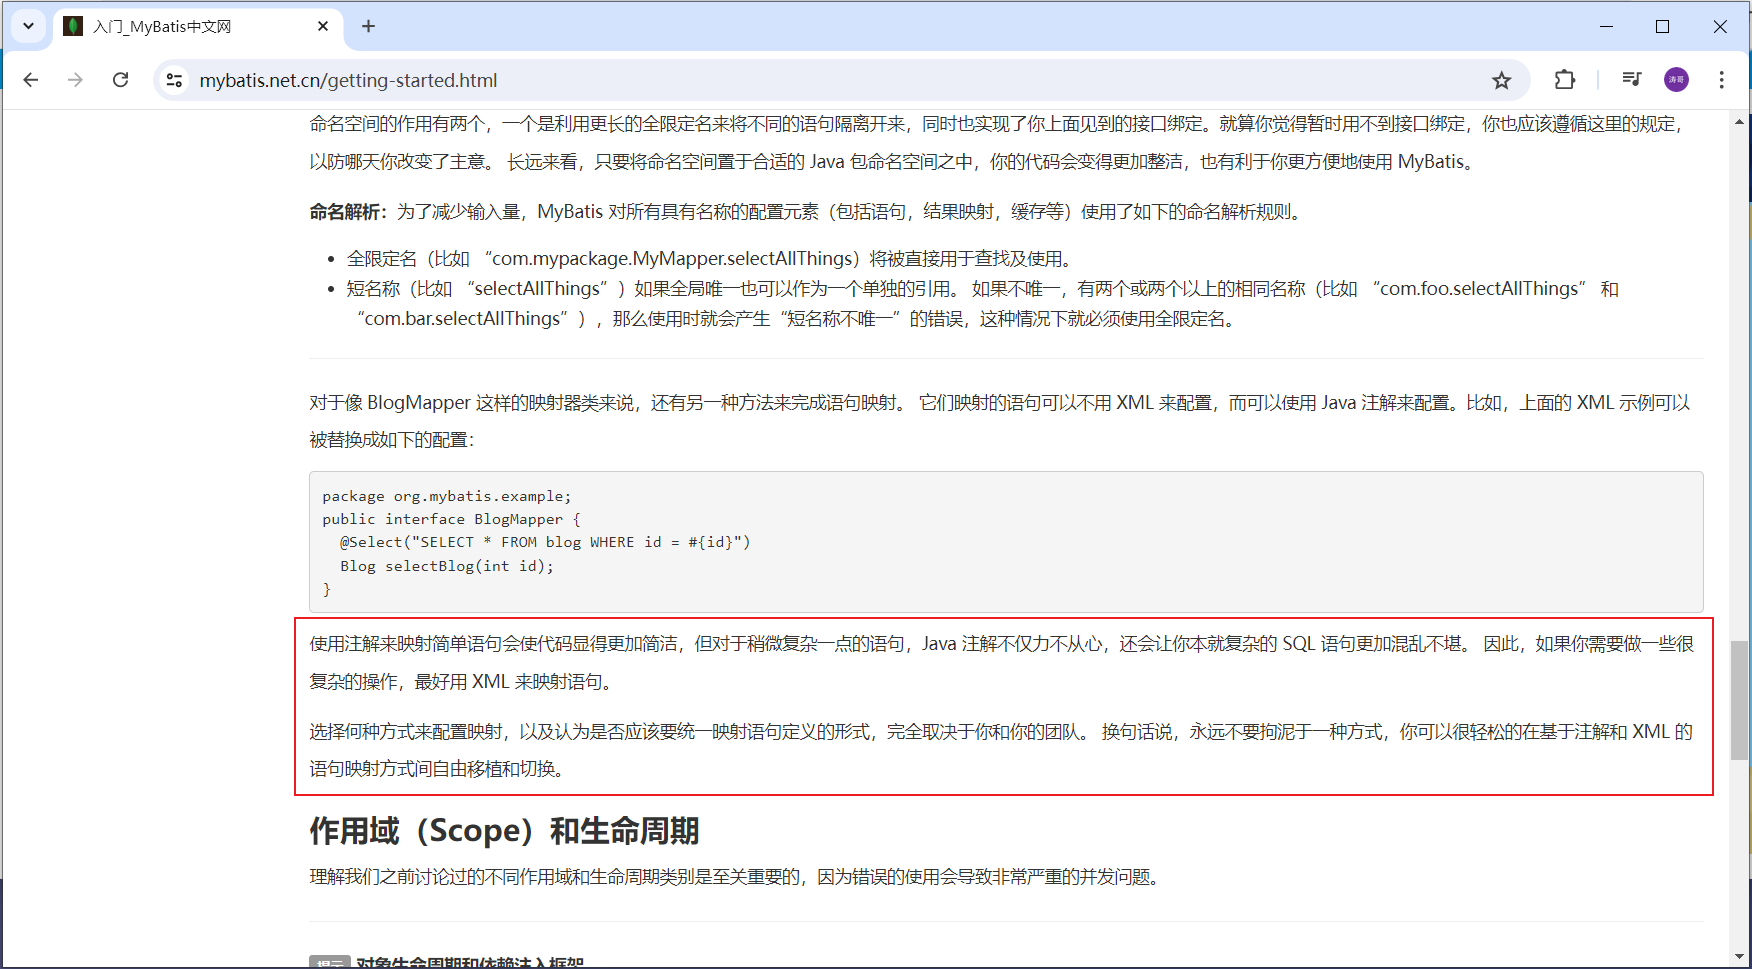

<strong>结论：</strong>使用Mybatis的注解，主要是来完成一些简单的增删改查功能。如果需要实现复杂的SQL功能，建议使用XML来配置映射语句。


## 4 SpringBoot配置文件


### 4.1 介绍

前面我们一直使用springboot项目创建完毕后自带的<code>application.properties</code>进行属性的配置，而如果在项目中，我们需要配置大量的属性，采用properties配置文件这种 <code>key=value</code> 的配置形式，就会显得配置文件的层级结构不清晰，也比较臃肿。

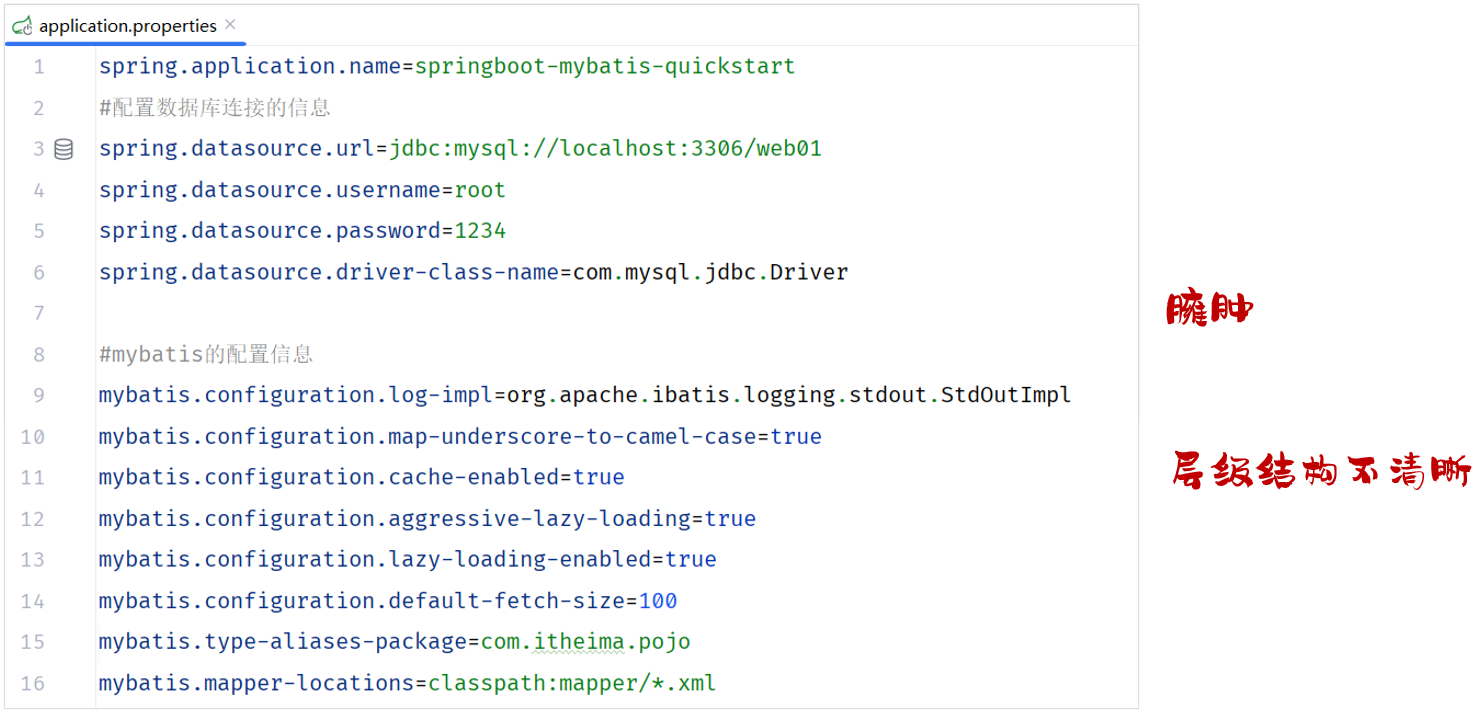

那其实呢，在springboot项目当中是支持多种配置方式的，除了支持properties配置文件以外，还支持另外一种类型的配置文件，就是我们接下来要讲解的yml格式的配置文件。yml格式配置文件名字为：<code>application.yaml</code> , <code>application.yml</code> 这两个配置文件的后缀名虽然不一样，但是里面配置的内容形式都是一模一样的。

我们可以来对比一下，采用 <code>application.properties</code> 和 <code>application.yml</code> 来配置同一段信息(数据库连接信息)，两者之间的配置对比：

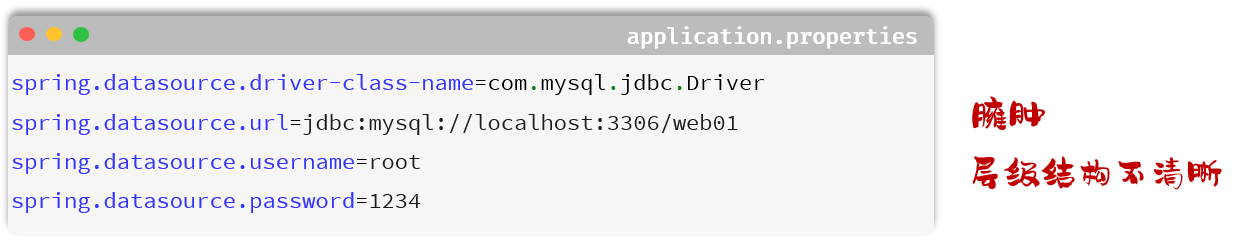

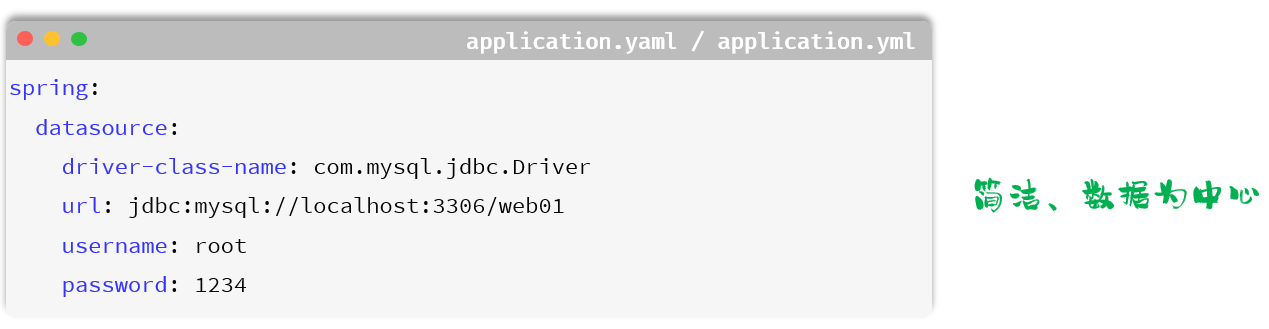

> 在项目开发中，我们推荐使用application.yml配置文件来配置信息，简洁、明了、以数据为中心。


### 4.2 语法

简单的了解过springboot所支持的配置文件，以及不同类型配置文件之间的优缺点之后，接下来我们就来了解下yml配置文件的基本语法：

- 大小写敏感
- 数值前边必须有空格，作为分隔符
- 使用缩进表示层级关系，缩进时，不允许使用Tab键，只能用空格（idea中会自动将Tab转换为空格）
- 缩进的空格数目不重要，只要相同层级的元素左侧对齐即可
- <code>&#35;</code>表示注释，从这个字符一直到行尾，都会被解析器忽略

**YAML 补充：**映射键后写半角冒号加空格，如 `port: 8080`；同级缩进一致，建议每级 2 个空格，不能使用真实 Tab。`#` 在注释位置表示注释，字符串中的 `#`、`: ` 等可通过引号避免歧义。密码、手机号、编号、URL 等字符串建议加引号；YAML 版本和解析器对前导 0、布尔值等的隐式转换存在差异，不应把所有前导 0 都一概解释为八进制。

```yaml
account:
  code: '0123'
  password: 'a: b # c'
  enabled: true
```

短横线列表本身表示 YAML 序列；绑定成 Java 的 List 还是 Set，取决于接收属性类型，并非写上短横线就天然去重。

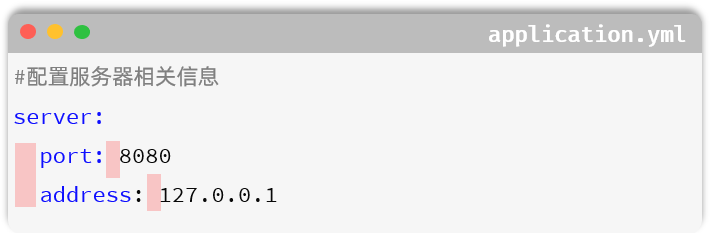

了解完yml格式配置文件的基本语法之后，接下来我们再来看下yml文件中常见的数据格式。在这里我们主要介绍最为常见的两类：

1. 定义对象或Map集合
2. 定义数组、list或set集合

- 对象/Map集合

````yaml
user:
  name: zhangsan
  age: 18
  password: 123456
````

- 数组/List/Set集合

````yaml
hobby: 
  - java
  - game
  - sport
````

> 在yml格式的配置文件中，如果配置项的值是以 0 开头的，值需要使用 '' 引起来，因为以0开头在yml中表示8进制的数据。


### 4.3 案例

熟悉完了yml文件的基本语法后，我们修改下之前案例中使用的配置文件，变更为application.yml配置方式：

1. 修改application.properties名字为：<code>&#95;application.properties</code>（名字随便更换，只要加载不到即可）
2. 创建新的配置文件： <code>application.yml</code>

- 原有的 <code>application.properties</code> 配置文件

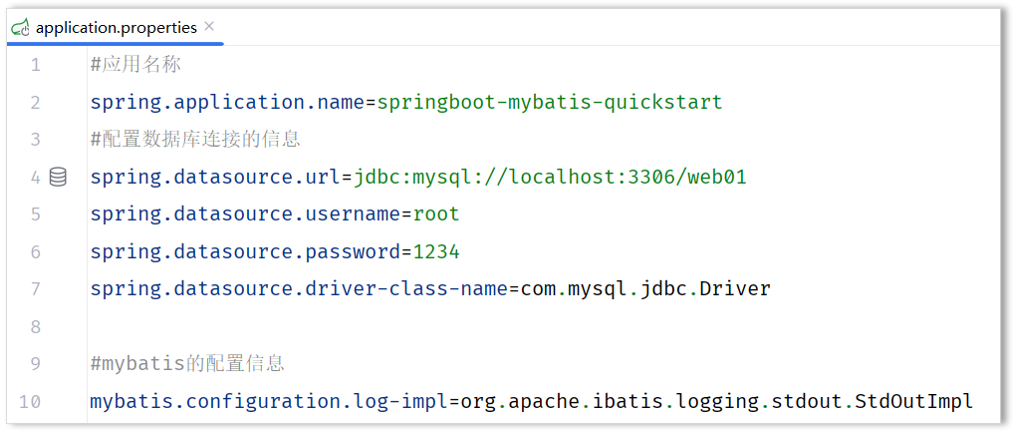

- 新建的 <code>application.</code>yml 配置文件

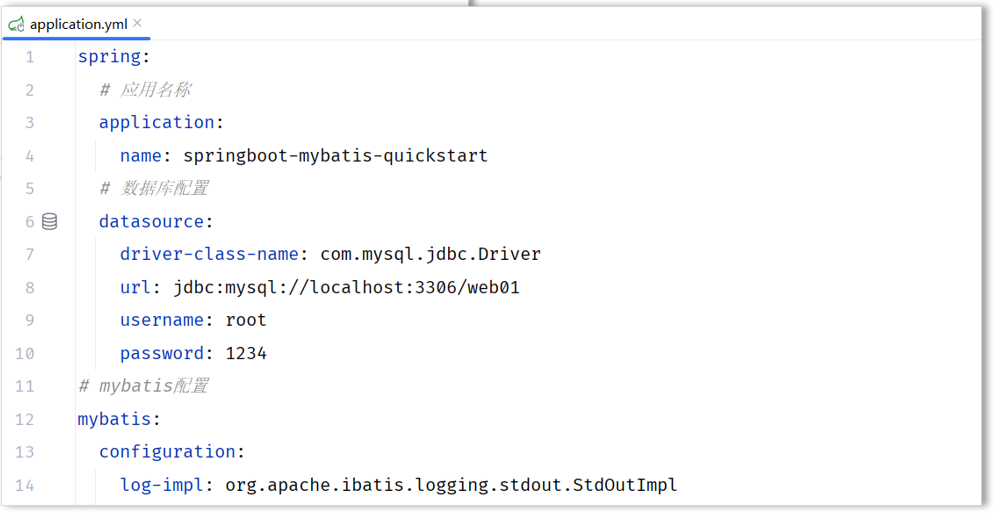

配置文件的内容如下：

````yaml
#数据源配置
spring:
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: jdbc:mysql://localhost:3306/web01
    username: root
    password: root@1234
#mybatis配置
mybatis:
  configuration:
    log-impl: org.apache.ibatis.logging.stdout.StdOutImpl
````

> **配置提醒：**该例仍写了 `web01` 和 `root@1234`，要与前面实际环境统一。properties 和 YAML 是等价的配置表达方式；同一位置同时存在时，Spring Boot 对 properties 的取值优先于 YAML，所以迁移时避免保留冲突配置。重命名后的 `_application.properties` 默认不作为主配置加载，但若显式导入则另当别论。第 5.1 节给出完整 YAML 和环境变量写法。


## 5 补充：把 JDBC 与 MyBatis 串成完整跟练

目标是验证“Java 参数 → SQL 执行 → 结果对象”这一条链路。使用专用练习库 `javaweb06_practice` 和表 `users`，不依赖原文中已被增删改过的 `web.user`。本节类、SQL、配置相互对应；代码应复制到 Maven 工程的相应文件，在 IDEA 或 Maven 中运行，不在 Notebook 的 Python 内核执行。

```text
mybatis-demo/
├─ pom.xml
├─ src/main/java/com/itheima/
│  ├─ DemoApplication.java
│  ├─ jdbc/JdbcDemo.java
│  ├─ pojo/User.java
│  └─ mapper/UserMapper.java
├─ src/main/resources/
│  ├─ application.yml
│  └─ mapper/UserMapper.xml       ← 5.6 节才添加
└─ src/test/java/com/itheima/
   └─ UserMapperTest.java
```

这一版继续采用课程的明文密码模型来观察查询行为；真实登录需要密码哈希校验，不应直接复用此模型。Java 与 SQL 的练习数据均为虚构。


### 5.1 准备表、依赖和配置

**① 在 MySQL 8.x 客户端执行一次。**库已存在时先检查是否为自己的旧练习，或选择新的库名并同步修改连接 URL；不要把初始化脚本重复执行后误当成程序失败。
```sql
CREATE DATABASE javaweb06_practice CHARACTER SET utf8mb4;
USE javaweb06_practice;

CREATE TABLE users (
    id INT PRIMARY KEY AUTO_INCREMENT,
    username VARCHAR(20) NOT NULL UNIQUE,
    password VARCHAR(100) NOT NULL,
    name VARCHAR(20) NOT NULL,
    age TINYINT UNSIGNED
) ENGINE=InnoDB;

INSERT INTO users(username, password, name, age) VALUES
    ('daqiao', '123456', '大乔', 22),
    ('xiaoqiao', '123456', '小乔', 18),
    ('diaochan', '123456', '貂蝉', 24),
    ('lvbu', '123456', '吕布', 28),
    ('zhaoyun', '12345678', '赵云', 27);

SELECT COUNT(*) AS total FROM users; -- 5
SELECT id, username, name, age FROM users ORDER BY id;
```

这里补上 `NOT NULL UNIQUE`，让用户名唯一成为数据库规则。InnoDB 支持事务，后面的集成测试可以回滚 DML。表需预先建好，测试中不会执行 DDL。

**② `pom.xml`。**这是一组固定的教学复现版本：Java 17、Spring Boot 3.2.0、MyBatis starter 3.0.3。MySQL 驱动、Lombok、JUnit 等交给 Spring Boot 父 POM 管理版本，避免依赖之间任意混搭。已有第 04 章工程时，核对版本后合并依赖即可。
```xml
<?xml version="1.0" encoding="UTF-8"?>
<project xmlns="http://maven.apache.org/POM/4.0.0"
         xmlns:xsi="http://www.w3.org/2001/XMLSchema-instance"
         xsi:schemaLocation="http://maven.apache.org/POM/4.0.0 https://maven.apache.org/xsd/maven-4.0.0.xsd">
    <modelVersion>4.0.0</modelVersion>
    <parent>
        <groupId>org.springframework.boot</groupId>
        <artifactId>spring-boot-starter-parent</artifactId>
        <version>3.2.0</version>
        <relativePath/>
    </parent>
    <groupId>com.itheima</groupId>
    <artifactId>mybatis-demo</artifactId>
    <version>1.0-SNAPSHOT</version>
    <properties>
        <java.version>17</java.version>
    </properties>
    <dependencies>
        <dependency>
            <groupId>org.mybatis.spring.boot</groupId>
            <artifactId>mybatis-spring-boot-starter</artifactId>
            <version>3.0.3</version>
        </dependency>
        <dependency>
            <groupId>com.mysql</groupId>
            <artifactId>mysql-connector-j</artifactId>
            <scope>runtime</scope>
        </dependency>
        <dependency>
            <groupId>org.projectlombok</groupId>
            <artifactId>lombok</artifactId>
            <optional>true</optional>
        </dependency>
        <dependency>
            <groupId>org.springframework.boot</groupId>
            <artifactId>spring-boot-starter-test</artifactId>
            <scope>test</scope>
        </dependency>
    </dependencies>
    <build>
        <plugins>
            <plugin>
                <groupId>org.springframework.boot</groupId>
                <artifactId>spring-boot-maven-plugin</artifactId>
                <configuration>
                    <mainClass>com.itheima.DemoApplication</mainClass>
                </configuration>
            </plugin>
        </plugins>
    </build>
</project>
```

**③ `src/main/resources/application.yml`。**使用默认 HikariCP，先不切换 Druid。
```yaml
spring:
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: '${DB_URL:jdbc:mysql://127.0.0.1:3306/javaweb06_practice}'
    username: '${DB_USERNAME:root}'
    password: '${DB_PASSWORD}'

mybatis:
  configuration:
    log-impl: org.apache.ibatis.logging.stdout.StdOutImpl
```

`${DB_PASSWORD}` 在这里是 **Spring 配置占位符**，与 MyBatis SQL 中的 `${...}` 不是同一套机制；`${名称:默认值}` 表示环境中未提供时使用默认值。

在 IDEA 的 **Run/Debug Configurations → Environment variables** 中设置 `DB_PASSWORD` 为实际数据库密码，必要时设置 `DB_USERNAME`、`DB_URL`。JDBC main 和 JUnit 测试是不同运行配置，两者都要设置。终端运行 Maven 时，环境变量也必须在启动 Maven 的终端可见。第一次导入 POM 需要网络下载依赖。


### 5.2 JDBC：绑定参数、读取空值、自动关闭资源

**`src/main/java/com/itheima/jdbc/JdbcDemo.java`**。在 IDEA 中运行这个 main，使用上节 POM 的运行时类路径。它直接调用 JDBC，未启动 Spring；因此不会自动读取 application.yml，而是读取相同的环境变量及代码中的默认值。
```java
package com.itheima.jdbc;

import java.sql.Connection;
import java.sql.DriverManager;
import java.sql.PreparedStatement;
import java.sql.ResultSet;
import java.sql.SQLException;
import java.util.Optional;

public class JdbcDemo {
    // 查询结果只携带需要的字段，不打印密码
    public record UserView(Integer id, String username, String name, Integer age) {}

    private static String envOr(String key, String fallback) {
        String value = System.getenv(key);
        return value == null ? fallback : value;
    }

    private static Connection connect() throws SQLException {
        String password = System.getenv("DB_PASSWORD");
        if (password == null) {
            throw new IllegalStateException("请在运行配置中设置 DB_PASSWORD");
        }
        return DriverManager.getConnection(
                envOr("DB_URL", "jdbc:mysql://127.0.0.1:3306/javaweb06_practice"),
                envOr("DB_USERNAME", "root"), password);
    }

    public static Optional<UserView> find(String username, String password)
            throws SQLException {
        String sql = "SELECT id, username, name, age FROM users "
                + "WHERE username = ? AND password = ?";
        try (Connection conn = connect();
             PreparedStatement ps = conn.prepareStatement(sql)) {
            ps.setString(1, username);
            ps.setString(2, password);
            try (ResultSet rs = ps.executeQuery()) {
                if (!rs.next()) {
                    return Optional.empty();
                }
                return Optional.of(new UserView(
                        rs.getInt("id"), rs.getString("username"),
                        rs.getString("name"), rs.getObject("age", Integer.class)));
            }
        }
    }

    public static int updateAge(int id, int age) throws SQLException {
        String sql = "UPDATE users SET age = ? WHERE id = ?";
        try (Connection conn = connect();
             PreparedStatement ps = conn.prepareStatement(sql)) {
            ps.setInt(1, age);
            ps.setInt(2, id);
            return ps.executeUpdate();
        }
    }

    public static void main(String[] args) throws SQLException {
        System.out.println(find("daqiao", "123456"));
        System.out.println(find("daqiao", "wrong"));
        System.out.println(find("nobody", "' or '1' = '1"));
    }
}
```

| 调用 | 未修改的初始数据下预期 |
| --- | --- |
| `find("daqiao", "123456")` | Optional 中有 id=1、大乔、age=22 |
| `find("daqiao", "wrong")` | `Optional.empty` |
| 包含 SQL 片段的密码输入 | `Optional.empty`；仍是普通参数值 |

`Optional` 表达“可能没有结果”。SQL 异常继续抛出，不把连接失败伪装成查不到用户。用户名有唯一约束，因此这里使用 `if (rs.next())` 读取至多一行；列表查询应循环读取。

可选增改练习：在 main 末尾调用 `updateAge(1, 25)` 后重新查询，再用 `updateAge(1, 22)` 恢复样本。该方法的连接默认自动提交，所以执行成功后数据库会改变；仅阅读或运行当前 main 的三次查询不会改变数据。`return` 或异常离开 try 块时，资源仍会自动关闭。


### 5.3 MyBatis：引导类与实体类

**`src/main/java/com/itheima/DemoApplication.java`**：放在 mapper、pojo 的上层包，便于扫描。
```java
package com.itheima;

import org.springframework.boot.SpringApplication;
import org.springframework.boot.autoconfigure.SpringBootApplication;

@SpringBootApplication
public class DemoApplication {
    public static void main(String[] args) {
        SpringApplication.run(DemoApplication.class, args);
    }
}
```

**`src/main/java/com/itheima/pojo/User.java`**：字段对应 users 表；Lombok 简化访问方法。
```java
package com.itheima.pojo;

import lombok.Data;
import lombok.NoArgsConstructor;
import lombok.ToString;

@Data
@NoArgsConstructor
public class User {
    private Integer id;
    private String username;
    @ToString.Exclude
    private String password;
    private String name;
    private Integer age;
}
```

这里无需为每个实体添加 `@Component`。实体是承载一行数据的普通 Java 对象；Mapper 代理才由框架注册到 Spring 容器。移除 Lombok 时，需要自己补 getter/setter 和无参构造方法。


### 5.4 MyBatis：完整注解 Mapper

**`src/main/java/com/itheima/mapper/UserMapper.java`**。暂时不创建 XML；每个方法的 SQL、参数名和返回类型在同一处对照。
```java
package com.itheima.mapper;

import com.itheima.pojo.User;
import java.util.List;
import org.apache.ibatis.annotations.Delete;
import org.apache.ibatis.annotations.Insert;
import org.apache.ibatis.annotations.Mapper;
import org.apache.ibatis.annotations.Options;
import org.apache.ibatis.annotations.Param;
import org.apache.ibatis.annotations.Select;
import org.apache.ibatis.annotations.Update;

@Mapper
public interface UserMapper {
    @Select("SELECT id, username, name, age FROM users ORDER BY id")
    List<User> findAll();

    @Select("SELECT id, username, name, age FROM users WHERE id = #{id}")
    User findById(@Param("id") Integer id);

    @Select("SELECT id, username, name, age FROM users "
            + "WHERE username = #{username} AND password = #{password}")
    User findByUsernameAndPassword(@Param("username") String username,
                                   @Param("password") String password);

    @Insert("INSERT INTO users(username, password, name, age) "
            + "VALUES(#{username}, #{password}, #{name}, #{age})")
    @Options(useGeneratedKeys = true, keyProperty = "id")
    int insert(User user);

    @Update("UPDATE users SET age = #{age} WHERE id = #{id}")
    int updateAge(@Param("id") Integer id, @Param("age") Integer age);

    @Delete("DELETE FROM users WHERE id = #{id}")
    int deleteById(@Param("id") Integer id);
}
```

`findAll` 显式按 id 排序，列表的顺序才确定。查询省略 password 列，返回 User 中 password 为 null；这不影响 SQL 的 WHERE 对该列筛选。`insert` 接收一个对象，`#{age}` 对应 getter 暴露的属性；updateAge 有两个参数，使用显式 `@Param` 名称，而不是靠参数位置猜测。

```text
业务/测试调用 Mapper 方法
    → MyBatis 代理找到 SQL
    → #{} 转成 ? 并绑定参数
    → 从 DataSource 获取连接，经 JDBC 执行
    → 读取结果并映射成 User / List<User> / 行数
```

注解 SQL 只是 SQL 的存放方式，底层仍然使用 JDBC。连接的提交与释放还受 Spring 事务范围影响。


### 5.5 用一个集成测试完成 CRUD 闭环

**`src/test/java/com/itheima/UserMapperTest.java`**。测试自己创建记录并取得实际 id，不依赖之前运行过什么方法，也不硬编码“新插入的一定是第 6 行”。
```java
package com.itheima;

import com.itheima.mapper.UserMapper;
import com.itheima.pojo.User;
import java.util.UUID;
import org.junit.jupiter.api.Test;
import org.springframework.beans.factory.annotation.Autowired;
import org.springframework.boot.test.context.SpringBootTest;
import org.springframework.transaction.annotation.Transactional;
import static org.junit.jupiter.api.Assertions.*;

@SpringBootTest
@Transactional
class UserMapperTest {
    @Autowired
    private UserMapper userMapper;

    @Test
    void crudRoundTrip() {
        User user = new User();
        user.setUsername("demo_" + UUID.randomUUID().toString().substring(0, 8));
        user.setPassword("demo-only");
        user.setName("跟练用户");
        user.setAge(20);

        assertEquals(1, userMapper.insert(user));
        Integer id = user.getId();
        assertNotNull(id);

        User saved = userMapper.findById(id);
        assertNotNull(saved);
        assertEquals(user.getUsername(), saved.getUsername());
        assertEquals(Integer.valueOf(20), saved.getAge());
        assertTrue(userMapper.findAll().stream().anyMatch(u -> id.equals(u.getId())));

        User matched = userMapper.findByUsernameAndPassword(user.getUsername(), "demo-only");
        assertNotNull(matched);
        assertEquals(id, matched.getId());
        assertNull(userMapper.findByUsernameAndPassword(user.getUsername(), "wrong"));
        assertNull(userMapper.findByUsernameAndPassword(user.getUsername(), "' or '1' = '1"));

        assertEquals(1, userMapper.updateAge(id, 21));
        assertEquals(Integer.valueOf(21), userMapper.findById(id).getAge());

        assertEquals(1, userMapper.deleteById(id));
        assertNull(userMapper.findById(id));
        assertEquals(0, userMapper.deleteById(id));
    }
}
```

在 IDEA 运行此测试，或在设置好环境变量的终端、pom.xml 所在目录执行：

```text
mvn test -Dtest=UserMapperTest
```

预期是这一个测试通过，而非只出现“进程结束”。首次插入得到 1 行且 id 被回填；错误密码及注入字符串查不到数据；删除后再次删除得到 0。`@Transactional` 让该测试在 Spring 管理的事务内执行，Spring 测试框架默认在结束时回滚，即便中途断言失败也不会留下这次插入的数据。自增序列可能仍前进，出现 id 空洞正常，不要断言主键连续。

这段测试需要实际可连接的 MySQL，本次笔记整理没有执行数据库联调，以上是跟练时应核对的预期。


### 5.6 把 findAll 从注解迁移到 XML

XML 适合 SQL 更长、动态条件更多时维护。只迁移 `findAll`，其余 CRUD 继续保留注解；一个方法只能对应一份 SQL。

**① 在 UserMapper 中删除 findAll 上面的 `@Select`，保留方法签名。**

```java
List<User> findAll();
```

**② 新建 `src/main/resources/mapper/UserMapper.xml`。**
```xml
<?xml version="1.0" encoding="UTF-8"?>
<!DOCTYPE mapper
        PUBLIC "-//mybatis.org//DTD Mapper 3.0//EN"
        "https://mybatis.org/dtd/mybatis-3-mapper.dtd">
<mapper namespace="com.itheima.mapper.UserMapper">
    <select id="findAll" resultType="com.itheima.pojo.User">
        SELECT id, username, name, age
        FROM users
        ORDER BY id
    </select>
</mapper>
```

**③ 在现有 YAML 的 mybatis 节下增加 mapper-locations，不要再新建一个同名顶层键。**最终该部分为：

```yaml
mybatis:
  mapper-locations: 'classpath:mapper/*.xml'
  configuration:
    log-impl: org.apache.ibatis.logging.stdout.StdOutImpl
```

| 对应关系 | 本例 |
| --- | --- |
| XML 的位置 | resources 下的 mapper 目录，构建时复制到类路径 |
| mapper-locations | 与实际 XML 路径一致 |
| namespace | 接口全名 `com.itheima.mapper.UserMapper` |
| select 的 id | 方法名 `findAll` |
| resultType | 一行数据的类型 `com.itheima.pojo.User` |
| Mapper 返回类型 | 多行用 `List<User>` |

重新运行同一个 `crudRoundTrip`，它调用了 findAll，应仍通过。`target/classes/mapper/UserMapper.xml` 应存在；若报 Invalid bound statement，依次检查文件是否打包、路径、namespace 和 id。XML 内的 SQL 条件出现 `<` 时可写 `&lt;` 或局部 CDATA，避免被当作 XML 标签。


## 6 补充：按现象排查

先确认数据库客户端能用同一组主机、端口、库名、账号密码连接，再看 Java 的最底层异常原因。IDEA 的 SQL 提示连接和 application.yml 的运行连接是两份配置。

| 现象 / 报错 | 优先检查 |
| --- | --- |
| `No suitable driver` / 找不到驱动类 | 驱动依赖是否解析成功且在运行时类路径，URL 是否以 jdbc:mysql: 开头 |
| `Communications link failure` / Connection refused | MySQL 服务、地址、端口是否正确；能否通过客户端连接 |
| `Access denied for user` | 实际用户名、密码及来源主机权限，不要照抄讲义演示密码 |
| `Unknown database` / Table doesn't exist | 是否建库选库，是否混用了 web、web01、javaweb06_practice 及 user/users |
| `Unknown column 'gender'` | 本章表没有 gender，应使用 age；检查复制的 SQL 与实际表结构 |
| `Parameter ... not found` | `#{名称}` 是否与 `@Param` 或对象属性一致，嵌套对象是否缺少前缀 |
| Mapper 无法注入 | 是否有 MyBatis starter、`@Mapper` 或 `@MapperScan`，扫描包是否覆盖接口 |
| `Unable to find a @SpringBootConfiguration` | 测试包位置及引导类；必要时显式指定 `@SpringBootTest(classes=...)` |
| `Invalid bound statement (not found)` | XML 是否打包并加载，namespace 和方法 id 是否完全一致 |
| `Mapped Statements ... already contains key` | 同一方法是否同时保留了注解 SQL 与 XML SQL，XML 是否重复加载 |
| `TooManyResultsException` | 返回单对象的方法查询到多行；用户名是否有唯一约束，条件是否正确 |
| 查到行但部分属性为空 | SQL 是否选出了对应列、属性名/别名是否一致；必要时使用 resultMap |
| insert 成功但对象 id 为 null | 是否设置 useGeneratedKeys/keyProperty；数据库列是否自增 |
| delete/update 返回 0 | 实际 id 是否存在；日志参数是什么；不要依赖其他测试生成的固定 id |
| 连接池等待超时 | 是否有未关闭连接、长事务、慢 SQL 或负载过高；不能只无限调大连接数 |
| YAML 启动报解析错误 | 空格缩进、冒号空格、重复键、含特殊字符的字符串是否加引号 |
| 修改 YAML 后似乎没生效 | 是否仍存在同位置 properties、启用的 profile、环境变量或命令行覆盖 |
| 找不到 `DB_PASSWORD` | 当前 IDEA 运行配置或启动 Maven 的终端是否提供了该变量 |
| Lombok 的 getter/setter 不存在 | 依赖、注解处理是否生效，IDEA 与 Maven 的 JDK/构建配置是否一致 |

检查 AI 生成代码时，先核对表结构、依赖兼容性和文件位置，再核对 SQL 的绑定参数、资源关闭及返回行数；截图中的“成功”不能替代本机断言结果。


## 7 本章复习（补充）

| 要能解释的问题 | 回答要点 |
| --- | --- |
| JDBC、驱动、MyBatis、连接池各做什么？ | JDBC 规定接口；驱动连接具体数据库；MyBatis 管理 SQL/参数/结果映射；连接池复用物理连接 |
| JDBC 查询有哪几步？ | 取连接、准备语句、绑定参数、执行、遍历结果、关闭资源 |
| `executeQuery` 与 `executeUpdate` 有何不同？ | 查询返回 ResultSet；增删改返回行数 |
| 为什么要先 `rs.next()`？ | 光标初始在第一行之前；next 同时移动光标并判断是否有当前行 |
| 预编译为什么能防参数注入？ | 参数被当成数据而不改变 SQL 结构；其他拼接片段仍需控制 |
| `#{}` 与 `${}` 有什么区别？ | 前者参数绑定，后者直接拼接；值优先用前者，标识符需固定映射/白名单 |
| 为什么用了连接池还要 close？ | 归还逻辑连接供复用，忘记归还会耗尽池；空闲回收不等于防止所有泄漏 |
| `@Param` 解决什么问题？ | 给方法参数明确命名，让 SQL 按稳定名称取值 |
| 查询单对象与集合怎么选？ | 返回单对象须保证至多一行；多行用 List，resultType 仍指每行类型 |
| XML 为什么找不到 SQL？ | 文件必须在类路径且被加载，namespace 与接口全名、id 与方法名一致 |
| 插入返回的 1 是主键吗？ | 1 是影响行数；主键通过生成键配置回填到对象属性 |
| properties 与 YAML 有何区别？ | 配置信息可以等价，YAML 用缩进表达结构；同位置冲突需留意加载优先级 |

**面试提示**：用“Mapper 调用如何最终到达数据库”串起 JDBC、参数绑定、DataSource 和结果映射。不要把“使用 PreparedStatement 就一定更快”“连接池能自动解决全部泄漏”“XML 必须与 Java 源文件放在一起”当成定律；解释成立的条件比只背结论更准确。

本章把第 05 章的 SQL 接入 Java。下一章进入部门管理实战，将 Mapper 放回 Controller → Service → Mapper 的请求处理流程中。


补充核对资料：[MyBatis 官方文档](https://mybatis.org/mybatis-3/zh/index.html)、[Mapper XML 配置](https://mybatis.org/mybatis-3/zh/sqlmap-xml.html)、[MyBatis Spring Boot Starter 兼容说明](https://mybatis.org/spring-boot-starter/mybatis-spring-boot-autoconfigure/)、[Druid Spring Boot 3](https://github.com/alibaba/druid/tree/master/druid-spring-boot-3-starter)。版本号用于课程复现，不表示当前最新发布版本。
